# Forecast Model for Confectionaries Are Us

## Step 1: Installing required imports

In [54]:
# used for dataframes, cleaning, transforming, merging datasets, handling misssing values, time-series operations.
import pandas as pd

# for numerical operations
import numpy as np

# used for plots and visualisation
import matplotlib.pyplot as plt

# used for statistical visualisation
import seaborn as sns

# datetime and delta imports will be used for comparing dates and scheduling future events
from datetime import datetime, timedelta

# use for splitting data into train and test groups
from sklearn.model_selection import train_test_split

# use for classification model
from sklearn.ensemble import RandomForestClassifier

# use for better performance of data
from sklearn.preprocessing import StandardScaler

# use for classification, predicting continuous values, statistics
from sklearn.model_selection import train_test_split, TimeSeriesSplit
from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.preprocessing import StandardScaler, PolynomialFeatures
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

# used for statistical analysis
from scipy import stats

# to keep notebook and output clean from libraries harmless warnings.
import warnings
warnings.filterwarnings('ignore')
warnings.simplefilter('ignore', FutureWarning)

# use for visualisation styling
plt.style.use('seaborn-v0_8-darkgrid')
sns.set_palette("husl")

# use for Display settings
pd.set_option('display.max_columns', None)
pd.set_option('display.max_rows', 100)
pd.set_option('display.float_format', '{:.2f}'.format)

print("Libraries are successfully imported!")
print(f"Pandas version: {pd.__version__}")
print(f"NumPy version: {np.__version__}")

Libraries are successfully imported!
Pandas version: 2.3.3
NumPy version: 2.3.5


## Step 2: Dataset Understanding 

### 2:1 Load dataset

In [55]:
# store data path for easy access
path = "/Users/Tippie/Desktop/DM project/Data mining dataset.xlsx"

# making data readable
df = pd.read_excel(path)

# Display message 
print("Dataset has been loaded successfully!")
print(f"\n{"Column Name": <30} {"Values": <15}")
print("-" * 40)
print(f"{'Dataset Shape':<28} {df.shape}")
print(f"{'Number of records':<30} {df.shape[0]:,}")
print(f"{'Number of features':<30} {df.shape[1]}")



Dataset has been loaded successfully!

Column Name                    Values         
----------------------------------------
Dataset Shape                (2000, 11)
Number of records              2,000
Number of features             11


### 2:2 Inspect dataset

In [56]:
# Display basic information about the dataset
print(f"Top 5 rows of the dataset:\n{"-" * 74}\n{df.head()}")
print("-" * 74)
print(f"\n\nBottom 5 rows of the dataset:\n{"-" * 74}\n{df.tail()}\n\n\n\n ")

Top 5 rows of the dataset:
--------------------------------------------------------------------------
     ID       Date Country(UK)     City Confectionary  Units Sold  \
0  1038 2023-12-31       Wales  Cardiff         Jelly     1914.00   
1  1111 2025-12-30     Ireland   Galway         jelly     2382.00   
2  1742 2025-11-30     Ireland     Cork       Caramel     2943.00   
3  1060 2025-11-29     England   London         Fudge     1793.00   
4   116 2025-10-27     Ireland   Galway         jelly     2621.00   

   Price per Unit (£)  Cost per Unit (£)  Revenue(£)  Cost(£)  Profit(£)  
0                5.46               2.23    10450.44  4268.22    6182.22  
1                5.34               2.38    12719.88  5669.16    7050.72  
2                5.30               2.25    15597.90  6621.75    8976.15  
3                5.20               2.17     9323.60  3890.81    5432.79  
4                4.74               2.30    12423.54  6028.30    6395.24  
---------------------------------

### 2:3 Datatype of the Dataset

In [57]:
# Understanding descriptive data information
print(f"\nDatatype of the Dataset to be analysed:\n{"-" * 60}")
df.info()


Datatype of the Dataset to be analysed:
------------------------------------------------------------
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2000 entries, 0 to 1999
Data columns (total 11 columns):
 #   Column              Non-Null Count  Dtype         
---  ------              --------------  -----         
 0   ID                  2000 non-null   int64         
 1   Date                2000 non-null   datetime64[ns]
 2   Country(UK)         2000 non-null   object        
 3   City                2000 non-null   object        
 4   Confectionary       2000 non-null   object        
 5   Units Sold          1901 non-null   float64       
 6   Price per Unit (£)  1901 non-null   float64       
 7   Cost per Unit (£)   1901 non-null   float64       
 8   Revenue(£)          2000 non-null   float64       
 9   Cost(£)             2000 non-null   float64       
 10  Profit(£)           2000 non-null   float64       
dtypes: datetime64[ns](1), float64(6), int64(1), object(3)
memo

## Step 3: Pre-processing

### 3:1 Categorical values

#### 3:1:1 Checking categorical values

In [58]:
# check repeated values for categorical data
print(f"\n\nList of Countries:\n{"-" * 24}\n{df["Country(UK)"].value_counts()}\n")
print("-" * 64)
print(f"\nList of Cities:\n{"-" * 24}\n{df["City"].value_counts()}\n")
print("-" * 64)
print(f"\nList of Confectionary:\n{"-" * 24}\n{df["Confectionary"].value_counts()}\n")
print("-" * 64)
print(f"\nIn the given dataset, it is seen that country and confectionary columns have repeated values due to lower and uppercase.") 
print(f"Hence, the count shows different values.")



List of Countries:
------------------------
Country(UK)
Ireland             416
England             401
Wales               392
Scotland            392
Northern Ireland    363
WALES                 9
NORTHERN IRELAND      9
SCOTLAND              7
ENGLAND               6
IRELAND               5
Name: count, dtype: int64

----------------------------------------------------------------

List of Cities:
------------------------
City
Swansea       154
Derry         131
Newport       125
Lisburn       123
Cardiff       122
Galway        119
Belfast       118
Edinburgh     116
Dundee        111
Dublin        106
Liverpool     100
Cork           98
Limerick       98
Glasgow        94
Leeds          80
London         79
Aberdeen       78
Birmingham     76
Manchester     72
Name: count, dtype: int64

----------------------------------------------------------------

List of Confectionary:
------------------------
Confectionary
Chew         256
Fudge        251
Biscuit      247
Jelly        24

#### 3:1:2 Changes of categorical values for repeated values

In [59]:
# changes to categorical data (resolving all mixed cases issues)
print(f"\nDataset after resolving upper and lowercase issue.")
df["Country"] = df["Country(UK)"].str.strip().str.title()
df["Confectionary"] = df["Confectionary"].str.strip().str.title()
print("-" * 64)
print(f"List of Countries:\n{"-" * 24}\n{df["Country"].value_counts()}\n")
print("-" * 64)
print(f"List of Confectionary:\n{"-" * 24}\n{df["Confectionary"].value_counts()}\n")
print("-" * 64)


Dataset after resolving upper and lowercase issue.
----------------------------------------------------------------
List of Countries:
------------------------
Country
Ireland             421
England             407
Wales               401
Scotland            399
Northern Ireland    372
Name: count, dtype: int64

----------------------------------------------------------------
List of Confectionary:
------------------------
Confectionary
Chew         269
Fudge        261
Jelly        257
Biscuit      251
Mint         247
Chocolate    245
Caramel      242
Toffee       228
Name: count, dtype: int64

----------------------------------------------------------------


## Step 4: Data Validation

### 4:1 Missing values

#### 4:1:1 Check missing values

Column Name          Missing Percentage
---------------------------------------------


                    Missing Count  Percentage
Units Sold                     99        4.95
Price per Unit (£)             99        4.95
Cost per Unit (£)              99        4.95


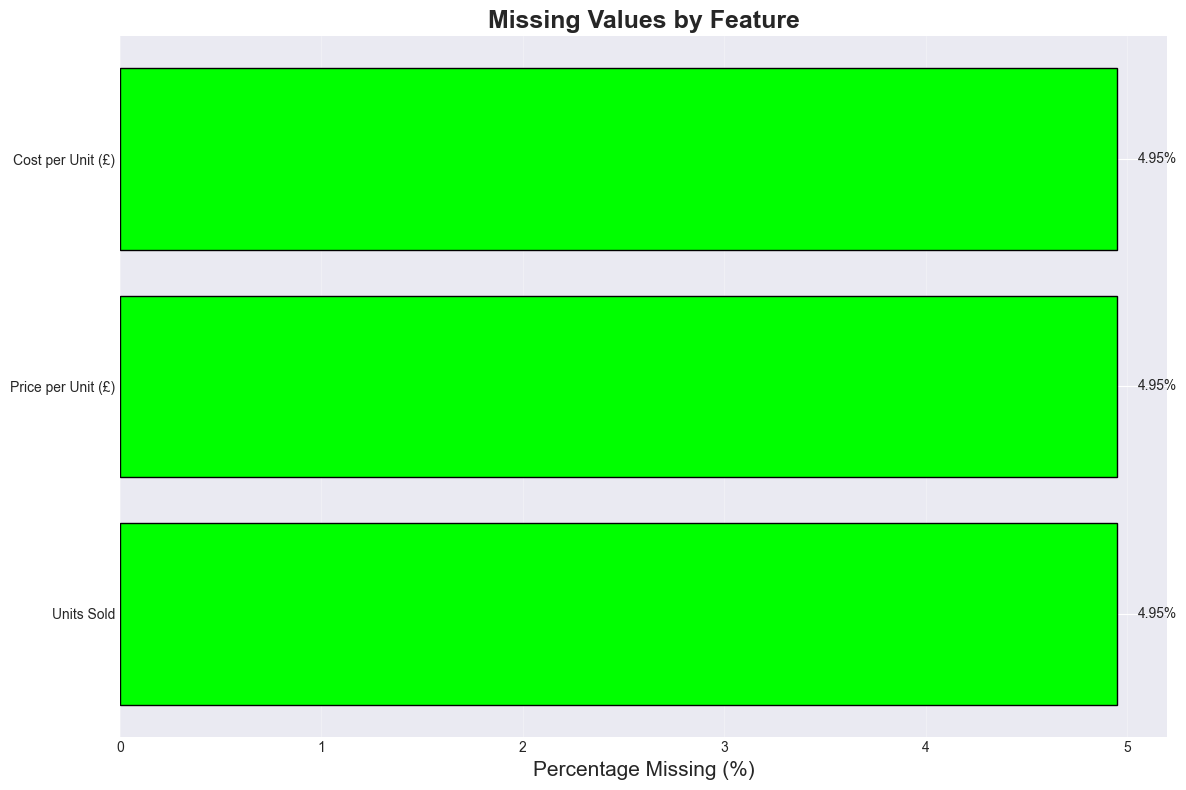

There are 3 columns with missing values which are 'Unit Sold', 'Price per unit', and Cost per unit' and all three columns have 4.95%.
Although it is less than 5 % the missing data is further investigated before deleting the rows.


In [60]:
# Checking missing values
missing_values_count = df.isnull().sum()
missing_percent = (df.isnull().sum()/len(df)) * 100

missing_data_df = pd.DataFrame({'Missing Count':missing_values_count,'Percentage': missing_percent})
no_nan_col_df= missing_data_df[~missing_data_df.index.str.startswith("cal_")]

print(f"{"Column Name": <20} {"Missing Percentage": <15}")
print("-" * 45)
print(no_nan_col_df[no_nan_col_df['Missing Count'] > 0].sort_values(by='Missing Count', ascending=False))


# Visualising missing values for the relevant columns
fig, ax = plt.subplots(figsize=(12, 8))
missing_cols = no_nan_col_df[no_nan_col_df['Missing Count'] > 0].sort_values(by='Missing Count', ascending=False)
if len(missing_cols) > 0:
    ax.barh(missing_cols.index, missing_cols['Percentage'], color='lime', edgecolor='black')
    ax.set_xlabel('Percentage Missing (%)', fontsize=15)
    ax.set_title('Missing Values by Feature', fontsize=18, fontweight='bold')
    ax.grid(axis='x', alpha=0.3)
    for i, v in enumerate(missing_cols['Percentage']):
        ax.text(v + 0.1, i, f'{v:.2f}%', va='center')
    plt.tight_layout()
    plt.show()
else:
    print("No missing values found in the dataset.")

print(f"There are 3 columns with missing values which are 'Unit Sold', 'Price per unit', and Cost per unit' and all three columns have 4.95%.")
print(f"Although it is less than 5 % the missing data is further investigated before deleting the rows.")

#### 4:1:2 Understanding zero and blank data before deleting

In [61]:
# to check whether the dataset is internally consistent meaning if the large differences between the for instance revenues indicate data errors. 

df['cal_Revenue'] = df['Units Sold'] * df['Price per Unit (£)'] 
df['cal_Cost'] = df['Units Sold'] * df['Cost per Unit (£)'] 
df['cal_Profit'] = df['cal_Revenue'] - df['cal_Cost'] 
revenue_diff = (df['Revenue(£)'] - df['cal_Revenue']).abs().describe() 
cost_diff = (df['Cost(£)'] - df['cal_Cost']).abs().describe() 
profit_diff = (df['Profit(£)'] - df['cal_Profit']).abs().describe()

# Display message
print("-" * 30)
print(f"Revenue Difference:\n{'-'*20}\n{revenue_diff}\n\n{'-'*30}\nCost Difference:\n{'-'*15}\n{cost_diff}\n\n{'-'*30}\nProfit Difference:\n{'-'*15}\n{profit_diff}")

print(f"\n\nIt is clear from the tables above that differences is zero which indicates the dataset is internally consistent.")
print(f"However, it is still unsure the impact of deleting the empty columns.")


------------------------------
Revenue Difference:
--------------------
count   1901.00
mean       0.00
std        0.00
min        0.00
25%        0.00
50%        0.00
75%        0.00
max        0.00
dtype: float64

------------------------------
Cost Difference:
---------------
count   1901.00
mean       0.00
std        0.00
min        0.00
25%        0.00
50%        0.00
75%        0.00
max        0.00
dtype: float64

------------------------------
Profit Difference:
---------------
count   1901.00
mean       0.00
std        0.00
min        0.00
25%        0.00
50%        0.00
75%        0.00
max        0.00
dtype: float64


It is clear from the tables above that differences is zero which indicates the dataset is internally consistent.
However, it is still unsure the impact of deleting the empty columns.


In [62]:
# converting blanks to NaN for uniform detection
changed_df = df.replace("", pd.NA)

# identifying rows that are zero or missing
numeric_cols = ["Units Sold", "Price per Unit (£)", "Cost per Unit (£)", "Revenue(£)", "Cost(£)", "Profit(£)"]

# masking 
masked_zero = (changed_df[numeric_cols].fillna(0) == 0).all(axis=1)
rows_with_zero = changed_df[masked_zero]

# understanding zero appeared in the data: does it appear randomly or not
countrywise_zeros = rows_with_zero["Country"].value_counts()
citywise_zeros = rows_with_zero["City"].value_counts()

print(f"Distribution of zeros countrywise and citywise: \n\n {countrywise_zeros}\n\n {citywise_zeros}")
print(f"\n\nThis shows the zeros in the columns are not random but clustered, which might be real no-sale days.")
print(f"Hence further analysis is required.")

Distribution of zeros countrywise and citywise: 

 Country
England             22
Northern Ireland    21
Ireland             21
Scotland            20
Wales               15
Name: count, dtype: int64

 City
Liverpool     8
Lisburn       8
Dundee        7
Limerick      7
Derry         7
Edinburgh     7
Galway        6
Belfast       6
Newport       6
Dublin        6
Cardiff       5
Leeds         4
Manchester    4
Glasgow       4
Swansea       4
Birmingham    3
London        3
Cork          2
Aberdeen      2
Name: count, dtype: int64


This shows the zeros in the columns are not random but clustered, which might be real no-sale days.
Hence further analysis is required.


In [63]:
# Comapring the neighbouring days (before and after)
# sorting dataset first by City and then by Date for each city to ensure previous and next rows belongs to same city in chronological order for zero or nan rows
df_sorted = changed_df.sort_values(["City", "Date"])

df_sorted["Value_before_zero"] = df_sorted.groupby("City")["Units Sold"].shift(1)
df_sorted["Value_after_zero"] = df_sorted.groupby("City")["Units Sold"].shift(-1)

sorted_masked_df = df_sorted[masked_zero][["Date", "City", "Units Sold", "Value_before_zero", "Value_after_zero"]]


print(sorted_masked_df.head(20))
print(f"\n\nThe table shows sales before and after the zero value which is high.")
print(f"This indicates the zero values are not real no-sale days but infact data-entry issue. Hence these zero rows can be deleted.")

           Date        City  Units Sold  Value_before_zero  Value_after_zero
1468 2022-04-11    Aberdeen         NaN            1791.00           3142.00
745  2024-03-03    Aberdeen         NaN            2044.00           2575.00
1578 2022-01-08     Belfast         NaN            1786.00           2153.00
976  2023-08-08     Belfast         NaN            2297.00           1339.00
938  2023-09-10     Belfast         NaN            1339.00           1774.00
800  2024-01-14     Belfast         NaN            2479.00           1494.00
562  2024-08-03     Belfast         NaN            1674.00           1210.00
464  2024-10-31     Belfast         NaN            1689.00           2190.00
1799 2021-06-20  Birmingham         NaN            2235.00               NaN
1753 2021-07-30  Birmingham         NaN                NaN           1521.00
1220 2022-12-22  Birmingham         NaN            2396.00           2431.00
1917 2021-03-12     Cardiff         NaN            1823.00           2384.00

In [64]:
# dropping those zero rows
df_clean = changed_df[masked_zero==False].copy()

# to identify all numeric fields are zero or missing, created changed version
changed_df = df_clean.copy()
masked_zero = (changed_df[numeric_cols].fillna(0) == 0).all(axis=1)


# Display message
print(f"\n{"Dataframe": <30} {"Values": <15}")
print("-" * 45)
print(f"{'Before cleaning':<20} {df.shape[0]} rows and {df.shape[1]} columns")
print(f"{'After cleaning':<20} {changed_df.shape[0]} rows and {changed_df.shape[1]} columns")


Dataframe                      Values         
---------------------------------------------
Before cleaning      2000 rows and 15 columns
After cleaning       1901 rows and 15 columns


## Step 5: Exploratory Data Analysis

### 5:1 Column Level Exploration

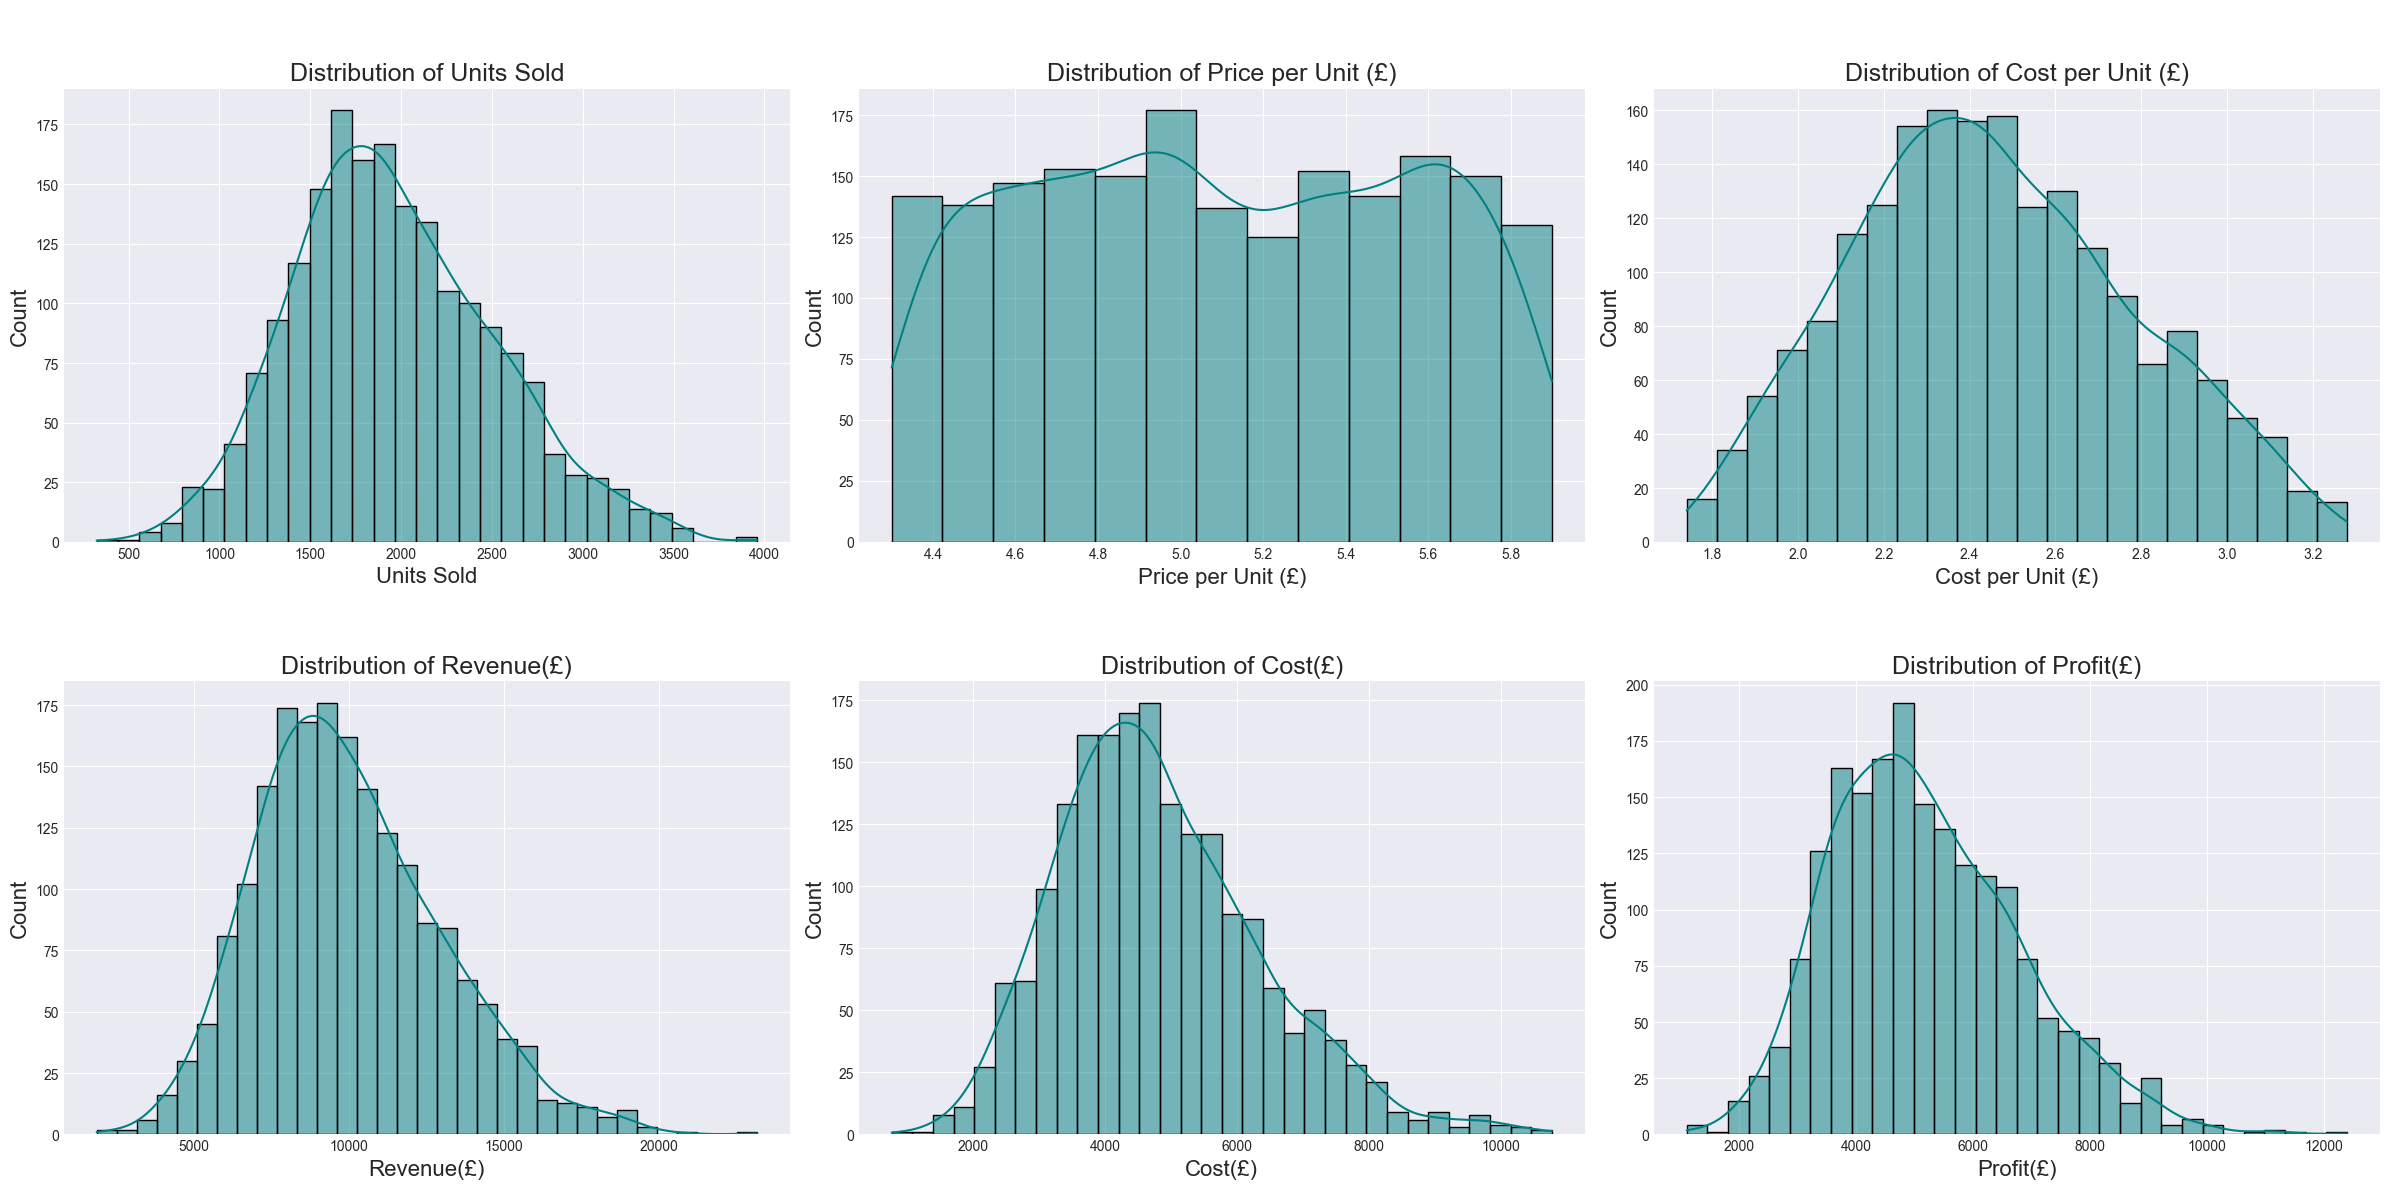


These distribution indicates consistent operational performance, which confirms that the dataset is suitable for forecasting model.


In [65]:
# Numeric columns
num_cols = ["Units Sold", "Price per Unit (£)", "Cost per Unit (£)", "Revenue(£)", "Cost(£)", "Profit(£)"]

# helps to understand shape of each variable such as skewness, outliers, and spread.
# Histogram
plt.figure(figsize=(24, 12))
for i, col in enumerate(num_cols, 1):
    plt.subplot(2,3,i)
    sns.histplot(changed_df[col], kde=True, color="teal")
    plt.xlabel(col, fontsize=16)
    plt.ylabel("Count", fontsize=16)
    plt.title(f"\n\nDistribution of {col}", fontsize="18")
plt.tight_layout()
plt.show()

print(f"\nThese distribution indicates consistent operational performance, which confirms that the dataset is suitable for forecasting model.")

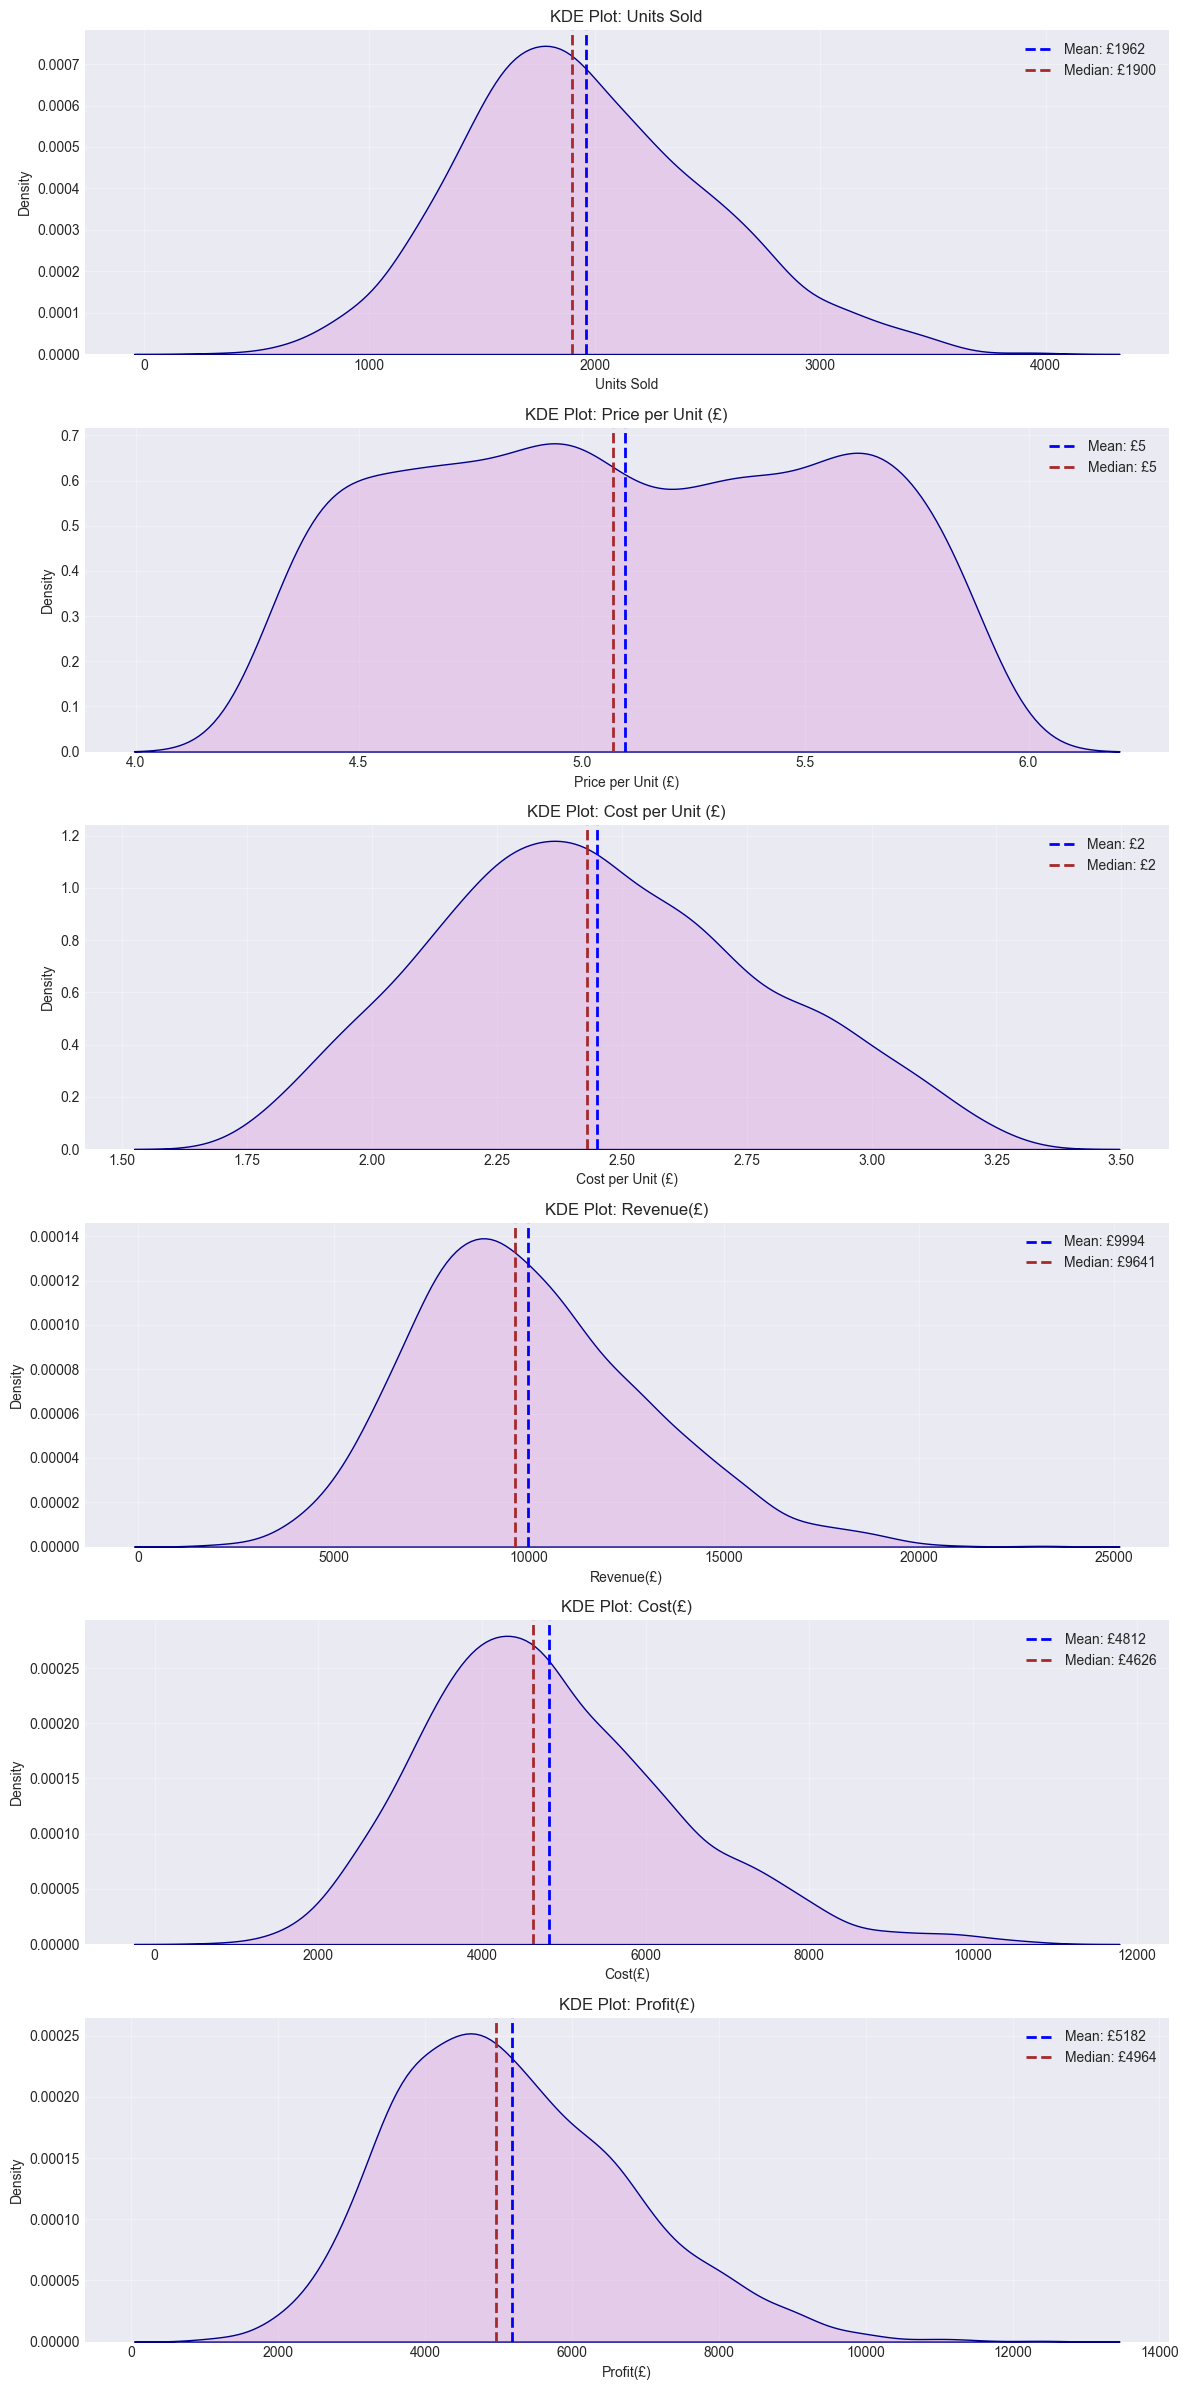


These patterns confirms that the dataset behaviour reflects natural business variability and occasional high-value days.


In [66]:

# KDE Plot to check if variable is heavy-tailed
fig, axes = plt.subplots(len(num_cols), 1, figsize=(12, 4 * len(num_cols))) 
for i, col in enumerate(num_cols): 
    sns.kdeplot(changed_df[col], fill=True, ax=axes[i], color="orchid", edgecolor="darkblue") 
    axes[i].set_title(f"KDE Plot: {col}") 
    axes[i].legend()
    axes[i].grid(alpha=0.3)
    
    # Add mean and median lines
    mean_val = changed_df[col].mean()
    median_val = changed_df[col].median()
    axes[i].axvline(mean_val, color='blue', linestyle='--', linewidth=2, label=f'Mean: £{mean_val:.0f}')
    axes[i].axvline(median_val, color='brown', linestyle='--', linewidth=2, label=f'Median: £{median_val:.0f}')
    axes[i].legend()
plt.tight_layout() 
plt.show()

print(f"\nThese patterns confirms that the dataset behaviour reflects natural business variability and occasional high-value days.")

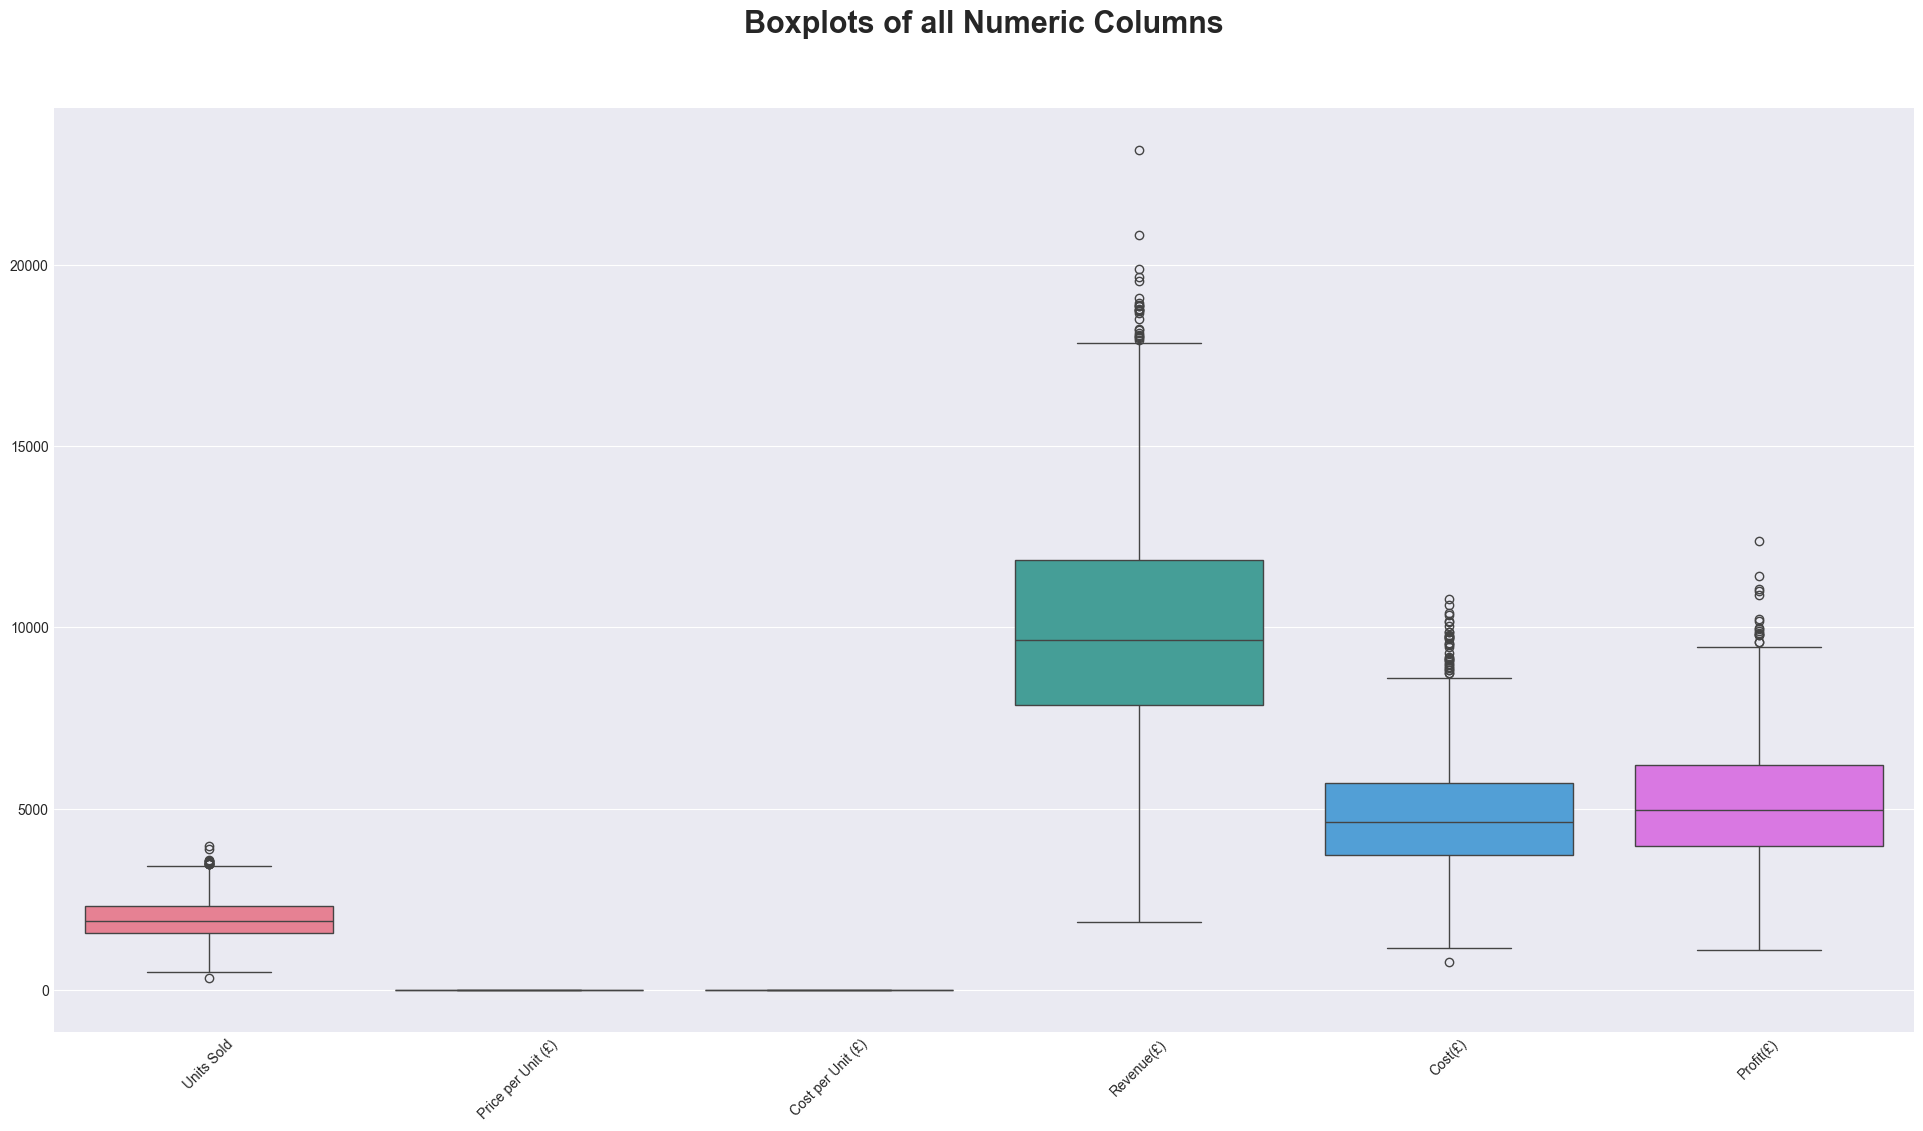


These outliers are consistent with real business events such as seasonal peaks or promotional spikes and not data-entry errors.


In [67]:
# Boxplot for quartiles, visual outliers
plt.figure(figsize=(24, 12)) 
sns.boxplot(data=changed_df[num_cols]) 
plt.title(f"Boxplots of all Numeric Columns\n\n", fontsize=22, fontweight='bold') 
plt.xticks(rotation=45) 
plt.show()

print(f"\nThese outliers are consistent with real business events such as seasonal peaks or promotional spikes and not data-entry errors.")

In [68]:
# Calculate interquartile range (IQR) for each numeric column and identify outliers (extreme values)
print(f"\n{'Column name': <20}{'Q1': <15}{'Q3': <15}{'IQR': <15}{'Lower Bound': <15}{'Upper Bound': <15}{'No. of Outliers': <15}")
print("-" * 115)
for col in num_cols:
    Q1 = changed_df[col].quantile(0.25)
    Q3 = changed_df[col].quantile(0.75)
    IQR = Q3 - Q1
    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR
    outliers = changed_df[(changed_df[col] < lower_bound) | (changed_df[col] > upper_bound)]
    outlier_pct = (len(outliers)/len(changed_df))*100

    # Display message
    print( f"{col:<20}" 
          f"{('£' + format(Q1, '.2f')):<15}" 
          f"{('£' + format(Q3, '.2f')):<15}" 
          f"{('£' + format(IQR, '.2f')):<15}" 
          f"{('£' + format(lower_bound, '.2f')):<15}" 
          f"{('£' + format(upper_bound, '.2f')):<15}" 
          f"{(str(len(outliers)) + ' (' + format(outlier_pct, '.2f') + '%)'):<15}" )
    


Column name         Q1             Q3             IQR            Lower Bound    Upper Bound    No. of Outliers
-------------------------------------------------------------------------------------------------------------------
Units Sold          £1575.00       £2325.00       £750.00        £450.00        £3450.00       14 (0.74%)     
Price per Unit (£)  £4.71          £5.50          £0.79          £3.52          £6.69          0 (0.00%)      
Cost per Unit (£)   £2.22          £2.67          £0.45          £1.55          £3.34          0 (0.00%)      
Revenue(£)          £7851.42       £11848.20      £3996.78       £1856.25       £17843.37      24 (1.26%)     
Cost(£)             £3733.52       £5707.52       £1974.00       £772.52        £8668.52       35 (1.84%)     
Profit(£)           £3983.52       £6210.54       £2227.02       £642.99        £9551.07       16 (0.84%)     


### 5:2 Temporal and Regional Exploration

#### 5:2:1 Country-level Analysis


Profit Analysis by Country:

                  Total_Profit  Average_Profit  Transaction_Count  Std_Dev
Country                                                                   
Ireland             2128586.84         5321.47                400  1676.00
Wales               2014039.21         5217.72                386  1655.99
Scotland            1979592.87         5223.20                379  1638.97
England             1938145.88         5034.15                385  1508.28
Northern Ireland    1790868.50         5102.19                351  1525.48


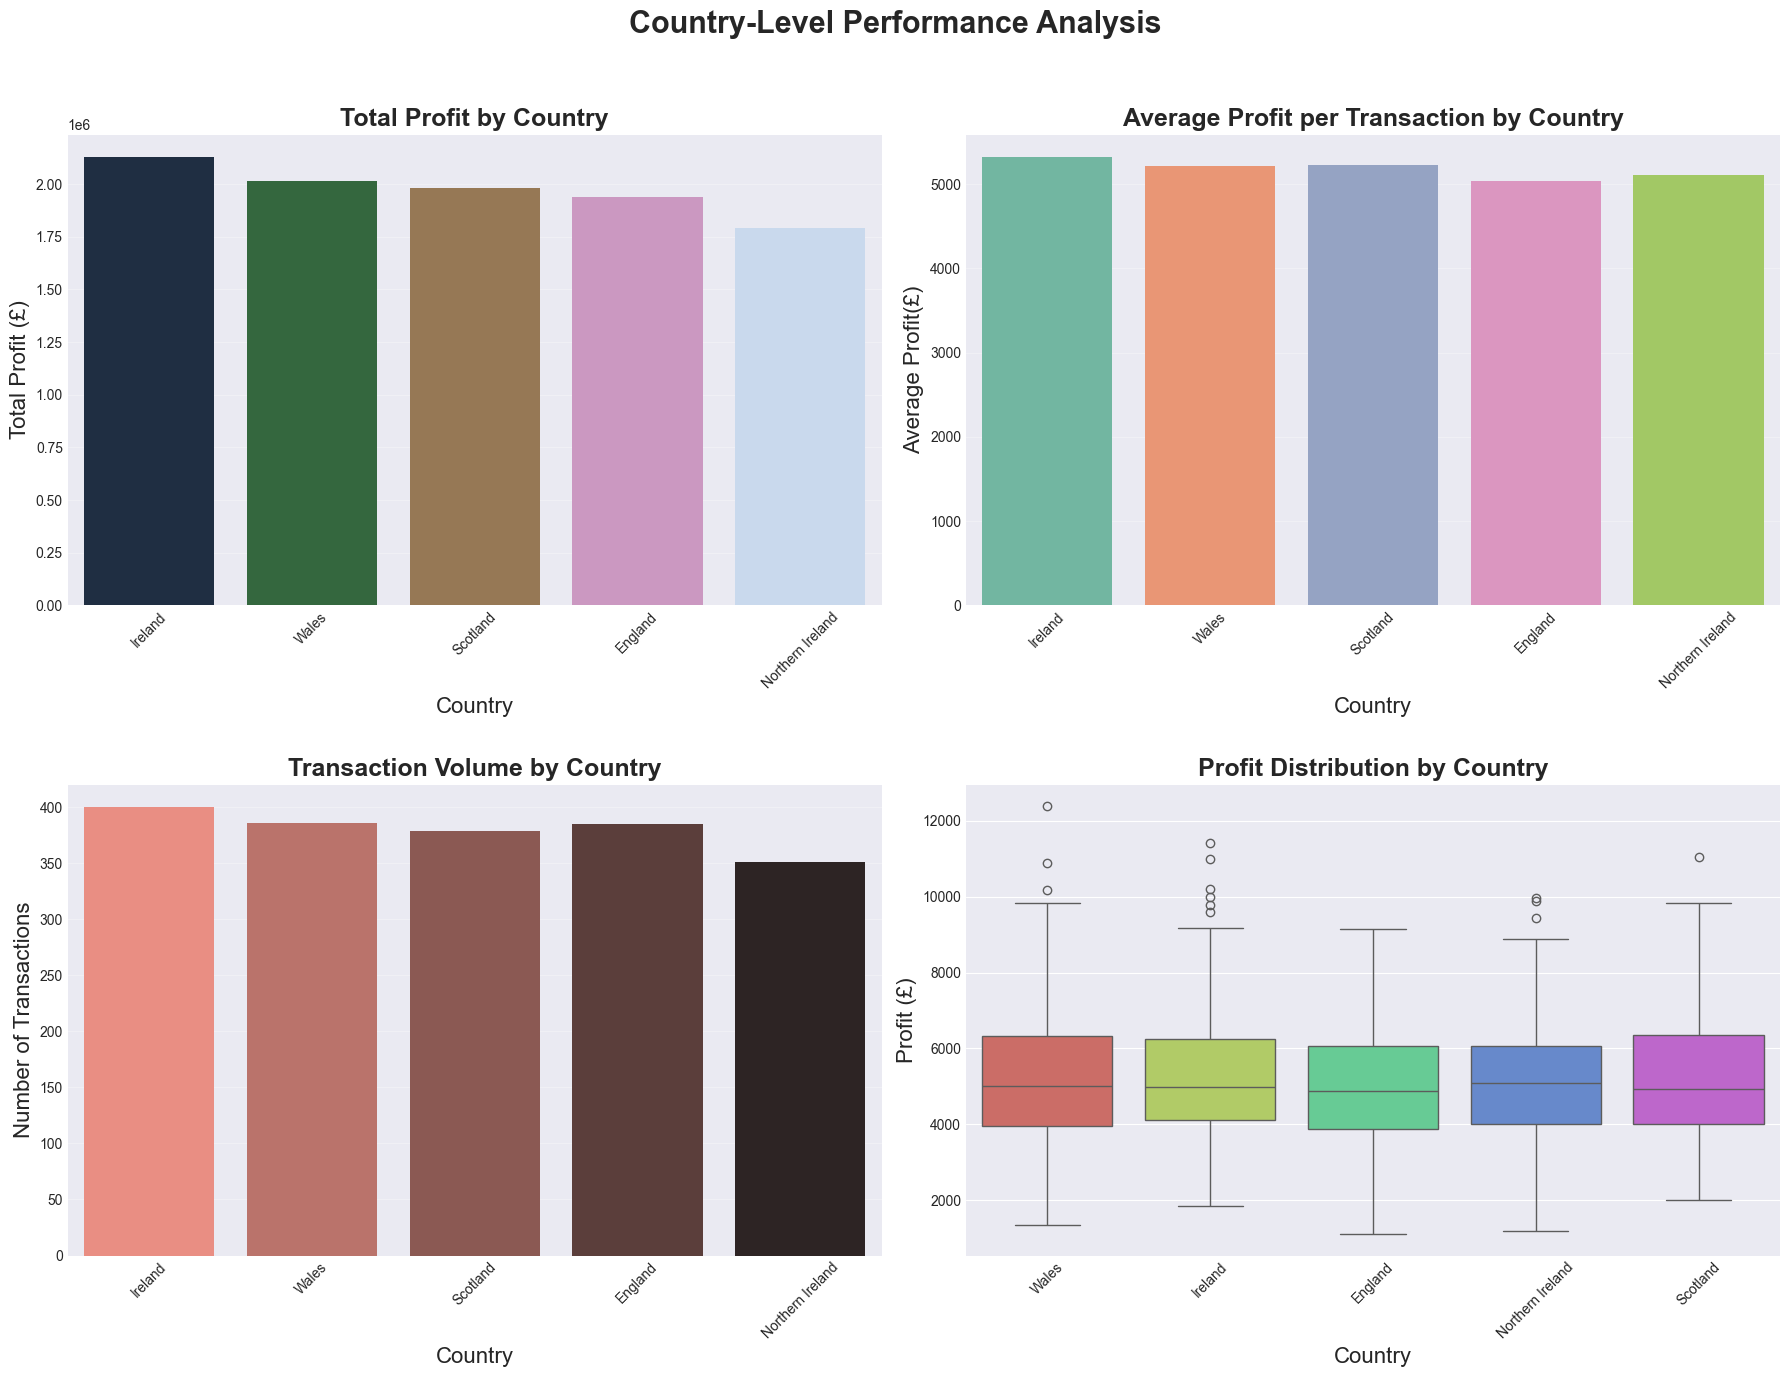

In [69]:
# Profit by Country Summary
country_profit = (changed_df.groupby('Country')['Profit(£)']
                  .agg(Total_Profit='sum', Average_Profit='mean', Transaction_Count='count', Std_Dev='std')
                  .sort_values('Total_Profit', ascending=False) ) 
print("\nProfit Analysis by Country:\n") 
print(country_profit) 
# Visualisation
fig, axes = plt.subplots(2, 2, figsize=(18, 14)) 
fig.suptitle('Country-Level Performance Analysis\n\n', fontsize=22, fontweight='bold') 
countries = country_profit.index 
# Total Profit
sns.barplot( x=countries, y=country_profit['Total_Profit'], ax=axes[0, 0], palette="cubehelix") 
axes[0, 0].set_title('Total Profit by Country', fontweight='bold', fontsize=18) 
axes[0, 0].set_xlabel('Country', fontsize=16) 
axes[0, 0].set_ylabel('Total Profit (£)', fontsize=16) 
axes[0, 0].tick_params(axis='x', rotation=45) 
axes[0, 0].grid(axis='y', alpha=0.3) 
# Average Profit
sns.barplot( x=countries, y=country_profit['Average_Profit'], ax=axes[0, 1], palette="Set2") 
axes[0, 1].set_title('Average Profit per Transaction by Country', fontweight='bold', fontsize=18) 
axes[0, 1].set_xlabel('Country', fontsize=16) 
axes[0, 1].set_ylabel('Average Profit(£)', fontsize=16) 
axes[0, 1].tick_params(axis='x', rotation=45) 
axes[0, 1].grid(axis='y', alpha=0.3) 
# Transaction Count
sns.barplot( x=countries, y=country_profit['Transaction_Count'], ax=axes[1, 0], palette="dark:salmon_r") 
axes[1, 0].set_title('\nTransaction Volume by Country', fontweight='bold', fontsize=18) 
axes[1, 0].set_xlabel('Country', fontsize=16) 
axes[1, 0].set_ylabel('Number of Transactions', fontsize=16) 
axes[1, 0].tick_params(axis='x', rotation=45) 
axes[1, 0].grid(axis='y', alpha=0.3) 
# Profit Distribution (Boxplot)
sns.boxplot( data=changed_df, x='Country', y='Profit(£)', ax=axes[1, 1], palette="hls") 
axes[1, 1].set_title('\nProfit Distribution by Country', fontweight='bold', fontsize=18) 
axes[1, 1].set_xlabel('Country', fontsize=16) 
axes[1, 1].set_ylabel('Profit (£)', fontsize=16) 
axes[1, 1].tick_params(axis='x', rotation=45) 
plt.tight_layout() 
plt.show()

#### 5:2:2 Product Analysis


Profit Analysis by Confectionery Type:

               Total_Profit  Average_Profit  Transaction_Count
Confectionary                                                 
Chocolate        1548111.74         6644.26                233
Caramel          1494559.23         6469.95                231
Biscuit          1285927.44         5403.06                238
Fudge            1182155.55         4672.55                253
Toffee           1180366.38         5464.66                216
Jelly            1132735.62         4680.73                242
Chew             1052636.27         4144.24                254
Mint              974741.07         4165.56                234


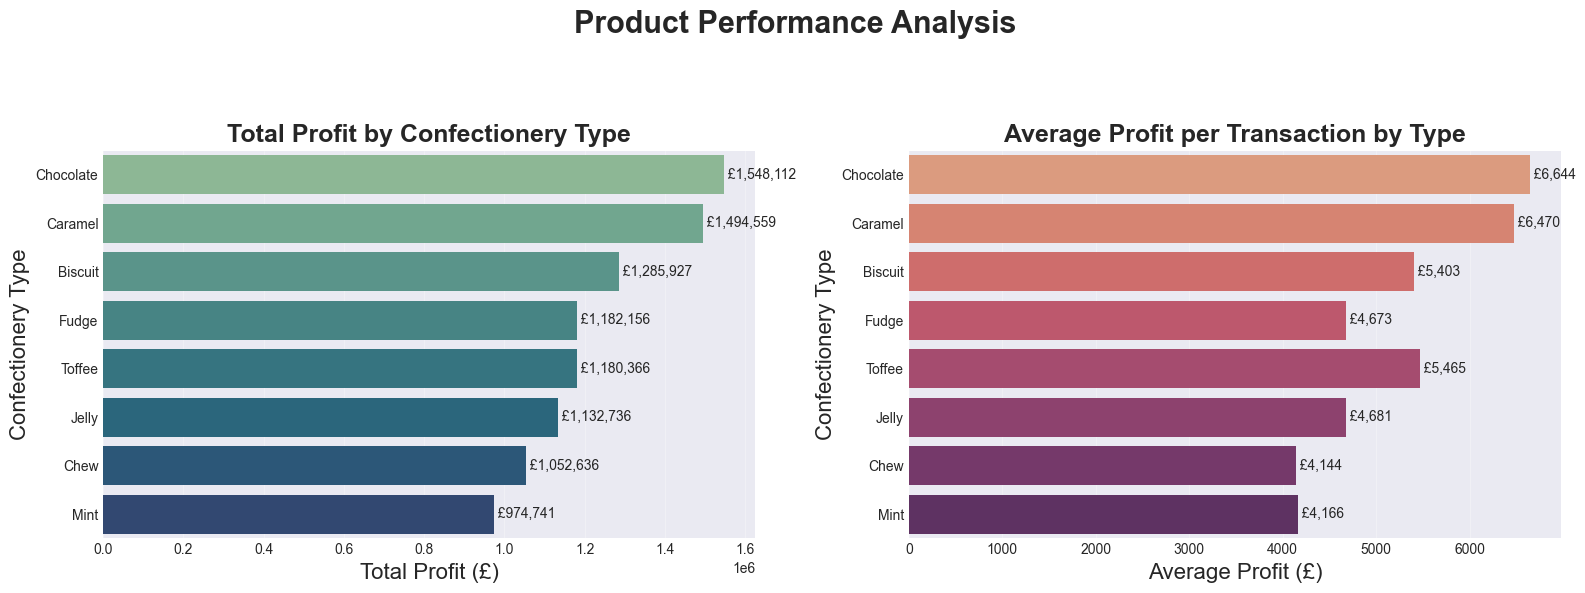

In [70]:
# Profit by Confectionery Type
product_profit = (changed_df.groupby('Confectionary')['Profit(£)']
                  .agg(Total_Profit='sum', Average_Profit='mean', Transaction_Count='count')
                  .sort_values('Total_Profit', ascending=False)) 
print("\nProfit Analysis by Confectionery Type:\n") 
print(product_profit) 
# Visualisation
fig, axes = plt.subplots(1, 2, figsize=(16, 6)) 
fig.suptitle('Product Performance Analysis\n\n', fontsize=22, fontweight='bold') 
#palette = sns.color_palette('flare', len(product_profit)) 
categories = product_profit.index 

# Total Profit
sns.barplot( x=product_profit['Total_Profit'], y=categories, ax=axes[0], palette="crest") 
axes[0].set_title('Total Profit by Confectionery Type', fontweight='bold', fontsize=18) 
axes[0].set_xlabel('Total Profit (£)', fontsize=16) 
axes[0].set_ylabel('Confectionery Type', fontsize=16) 
axes[0].grid(axis='x', alpha=0.3) 
# Add labels 
for i, v in enumerate(product_profit['Total_Profit']): 
    axes[0].text(v, i, f' £{v:,.0f}', va='center') 

# Average Profit
sns.barplot( x=product_profit['Average_Profit'], y=categories, ax=axes[1], palette="flare") 
axes[1].set_title('Average Profit per Transaction by Type', fontweight='bold', fontsize=18) 
axes[1].set_xlabel('Average Profit (£)', fontsize=16) 
axes[1].set_ylabel('Confectionery Type', fontsize=16) 
axes[1].grid(axis='x', alpha=0.3) 
# Add labels 
for i, v in enumerate(product_profit['Average_Profit']): axes[1].text(v, i, f' £{v:,.0f}', va='center') 
plt.tight_layout() 
plt.show()

#### 5:2:3 Profit by Date

Daily Aggregated Data Summary:

         Profit   Revenue      Cost  Transaction_Count
count   1159.00   1159.00   1159.00            1159.00
mean    8499.77  16392.78   7893.01               1.64
std     6062.38  11684.49   5691.20               1.00
min     1101.60   1869.48    767.88               1.00
25%     4732.72   9092.03   4329.75               1.00
50%     6866.70  13065.21   6222.96               1.00
75%    10970.80  20885.69   9981.70               2.00
max   123883.99 237822.67 113938.68              19.00
Date range: 2021-01-01 to 2025-12-30


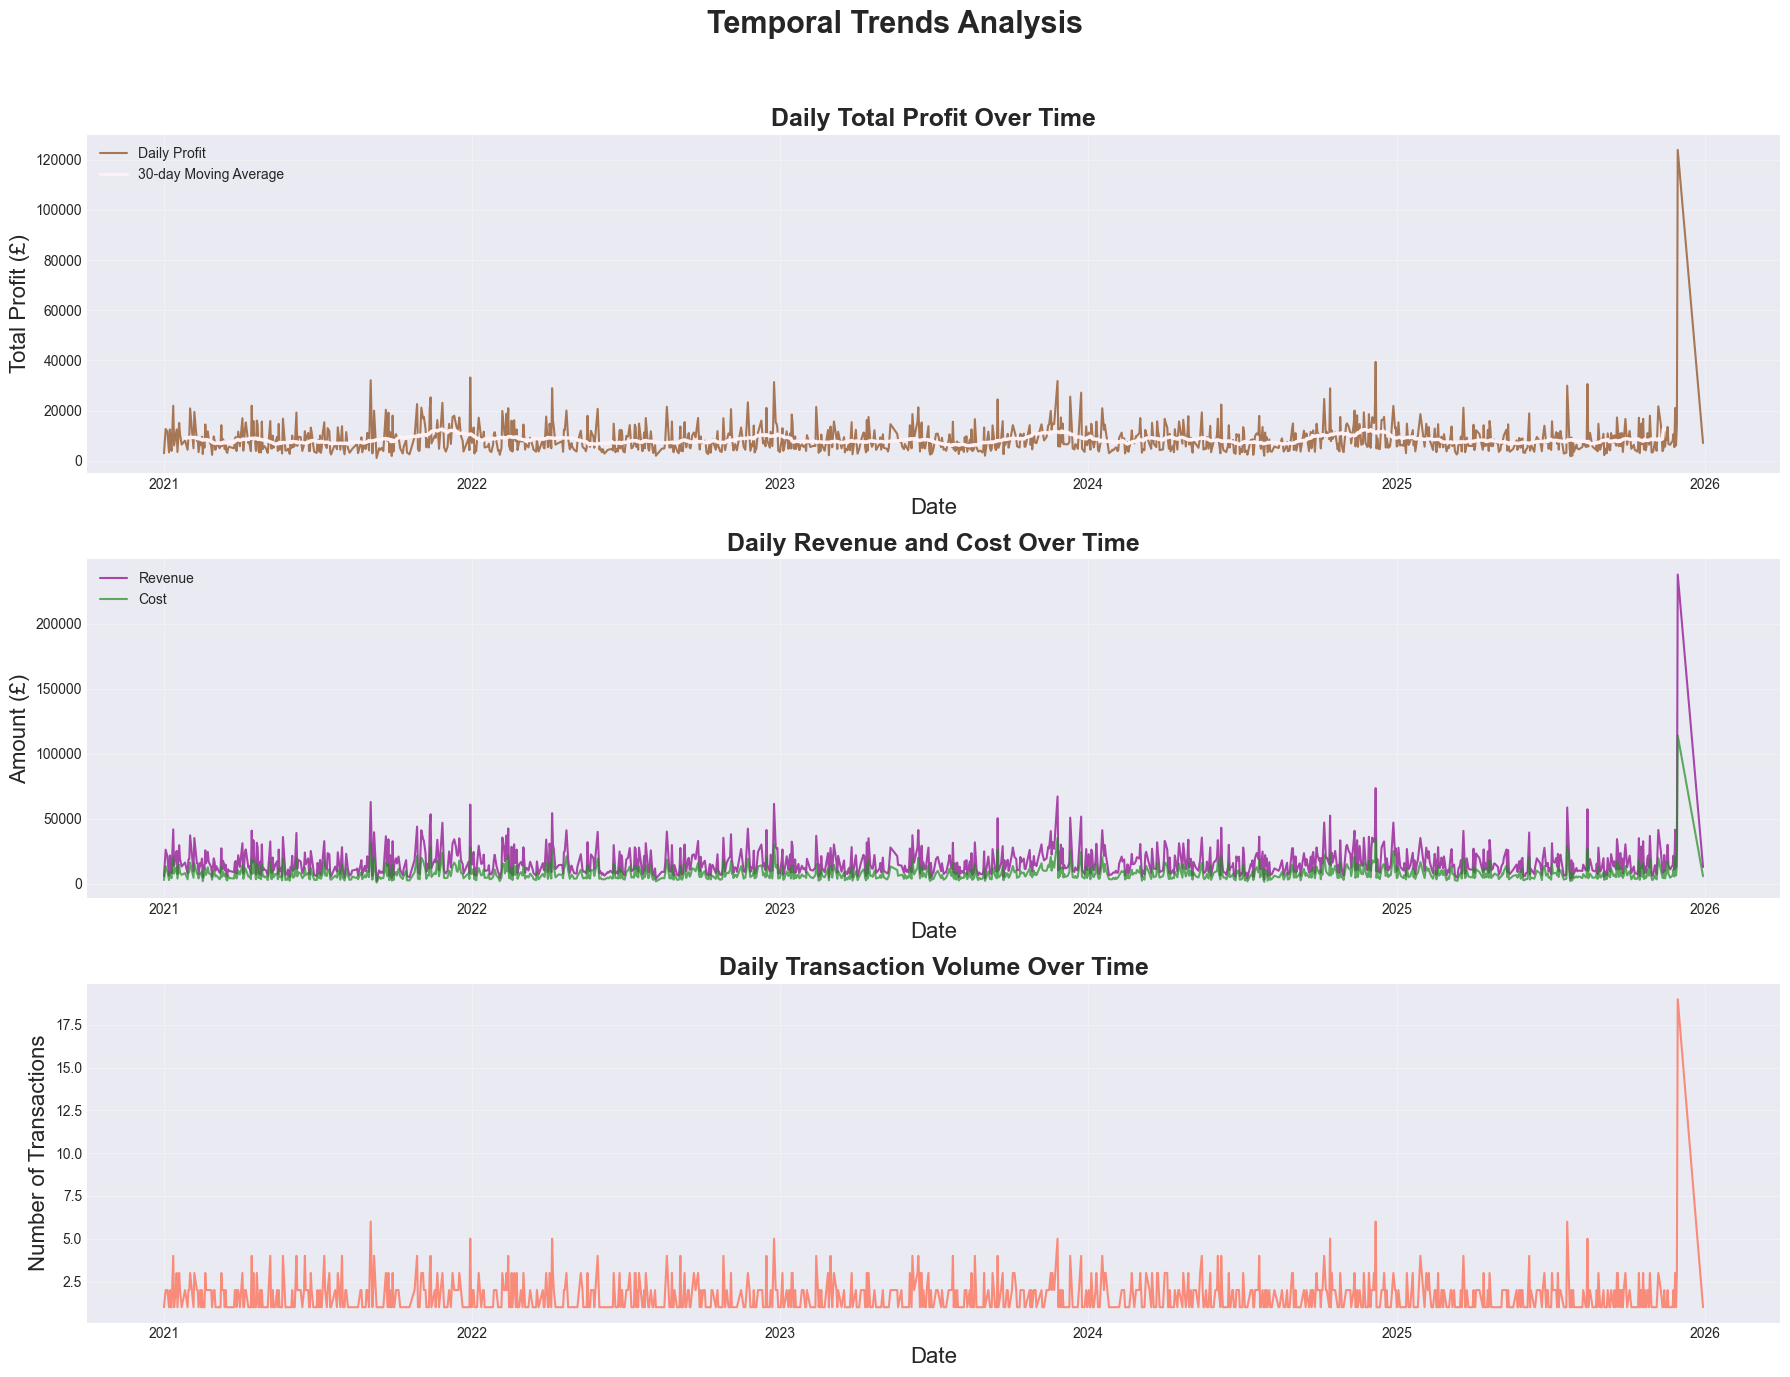

In [71]:
# Daily Aggregation
daily_profit = (changed_df.groupby('Date').agg(Profit=('Profit(£)', 'sum'),Revenue=('Revenue(£)', 'sum'),Cost=('Cost(£)', 'sum'),Transaction_Count=('ID', 'count')).sort_index())

print("Daily Aggregated Data Summary:\n")
print(daily_profit.describe())
print(f"Date range: {daily_profit.index.min().date()} to {daily_profit.index.max().date()}")

# Pre‑compute moving average (kept outside plotting)
daily_profit['mov_avg_30'] = daily_profit['Profit'].rolling(window=30, center=True).mean()

# Visualisation
fig, axes = plt.subplots(3, 1, figsize=(18, 14))
fig.suptitle('Temporal Trends Analysis\n\n', fontsize=22, fontweight='bold')

# Daily Profit
axes[0].plot(daily_profit.index, daily_profit['Profit'], 
             linewidth=1.5, color='SaddleBrown', alpha=0.7, label='Daily Profit')
axes[0].plot(daily_profit.index, daily_profit['mov_avg_30'], 
             linewidth=2.5, color='LavenderBlush', label='30-day Moving Average')

axes[0].set_title('Daily Total Profit Over Time', fontweight='bold', fontsize=18)
axes[0].set_xlabel('Date', fontsize=16)
axes[0].set_ylabel('Total Profit (£)', fontsize=16)
axes[0].grid(alpha=0.3)
axes[0].legend()

# Daily Revenue & Cost
axes[1].plot(daily_profit.index, daily_profit['Revenue'], 
             linewidth=1.5, color='DarkMagenta', alpha=0.7, label='Revenue')
axes[1].plot(daily_profit.index, daily_profit['Cost'], 
             linewidth=1.5, color='ForestGreen', alpha=0.7, label='Cost')

axes[1].set_title('Daily Revenue and Cost Over Time', fontweight='bold', fontsize=18)
axes[1].set_xlabel('Date', fontsize=16)
axes[1].set_ylabel('Amount (£)', fontsize=16)
axes[1].grid(alpha=0.3)
axes[1].legend()

# Daily Transaction Count
axes[2].plot(daily_profit.index, daily_profit['Transaction_Count'], 
             linewidth=1.5, color='Tomato', alpha=0.7)

axes[2].set_title('Daily Transaction Volume Over Time', fontweight='bold', fontsize=18)
axes[2].set_xlabel('Date', fontsize=16)
axes[2].set_ylabel('Number of Transactions', fontsize=16)
axes[2].grid(alpha=0.3)

plt.tight_layout()
plt.show()


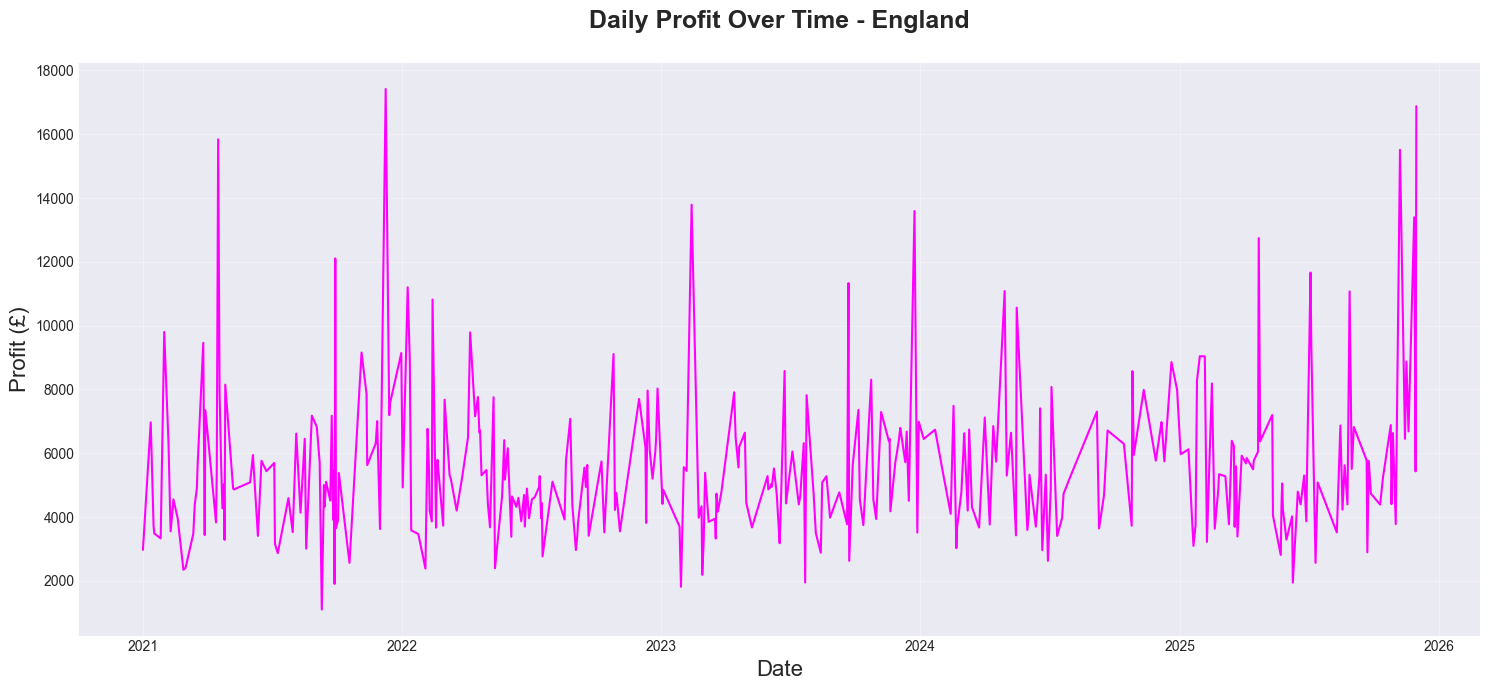

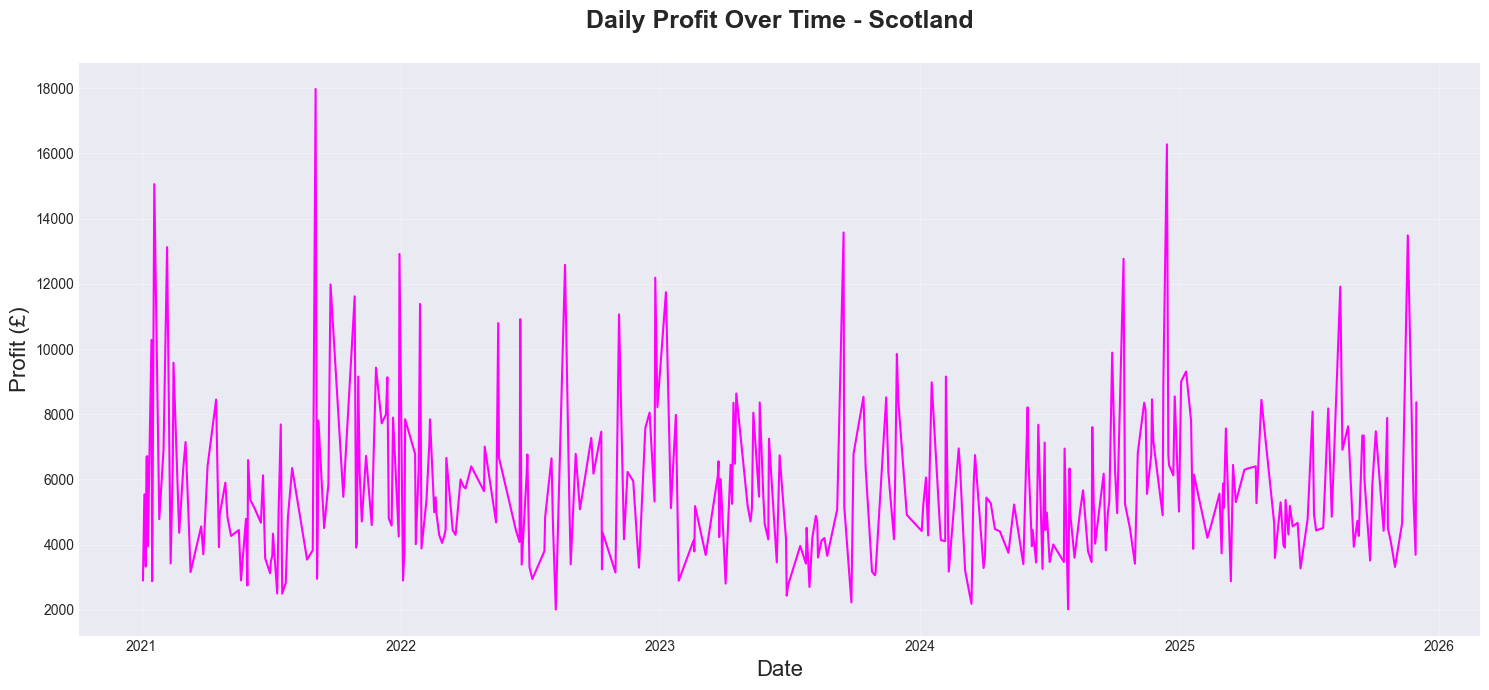

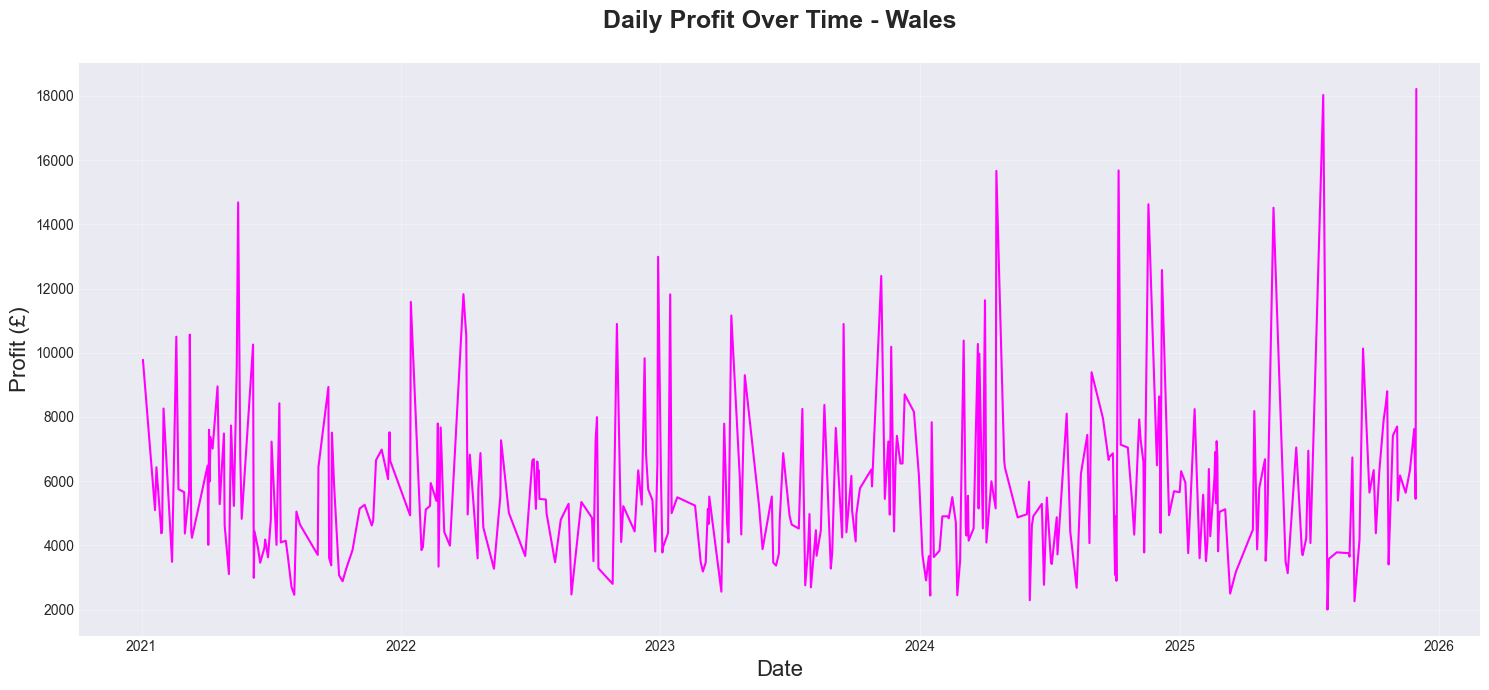

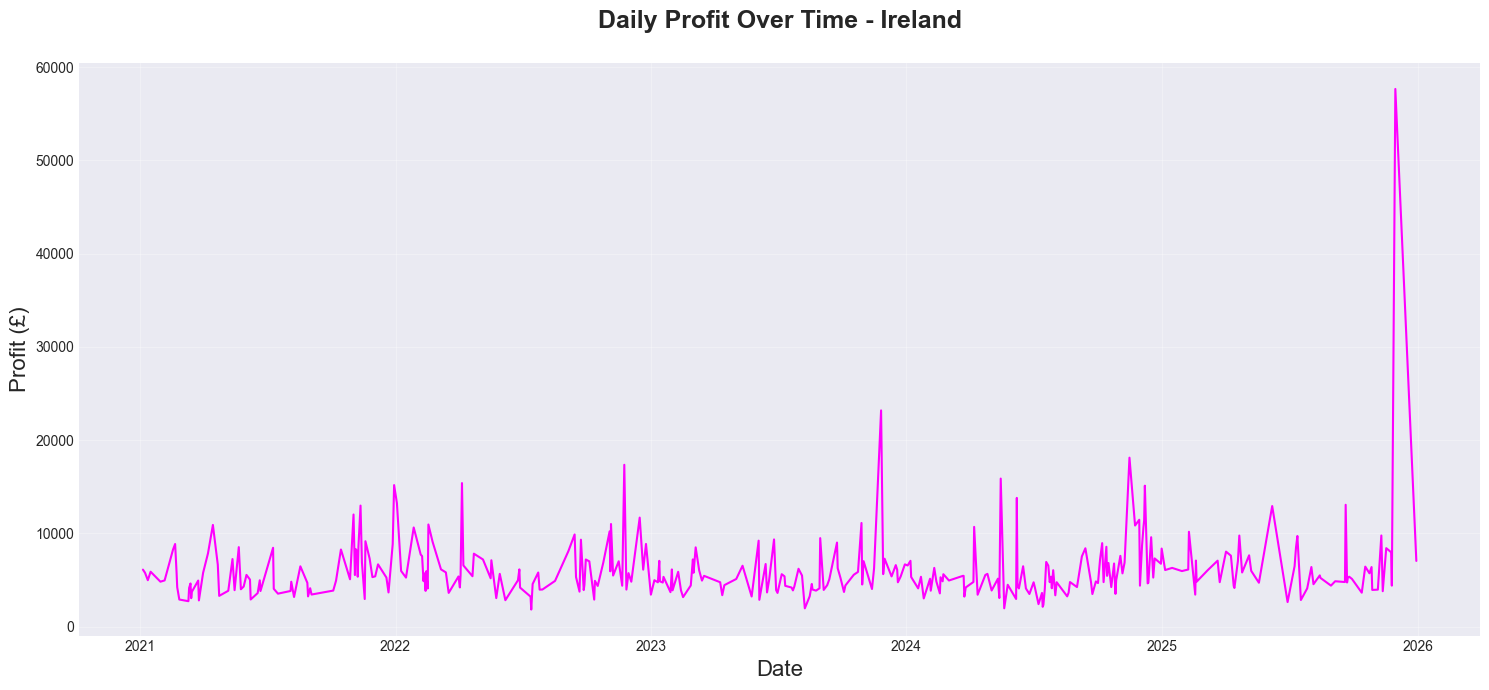

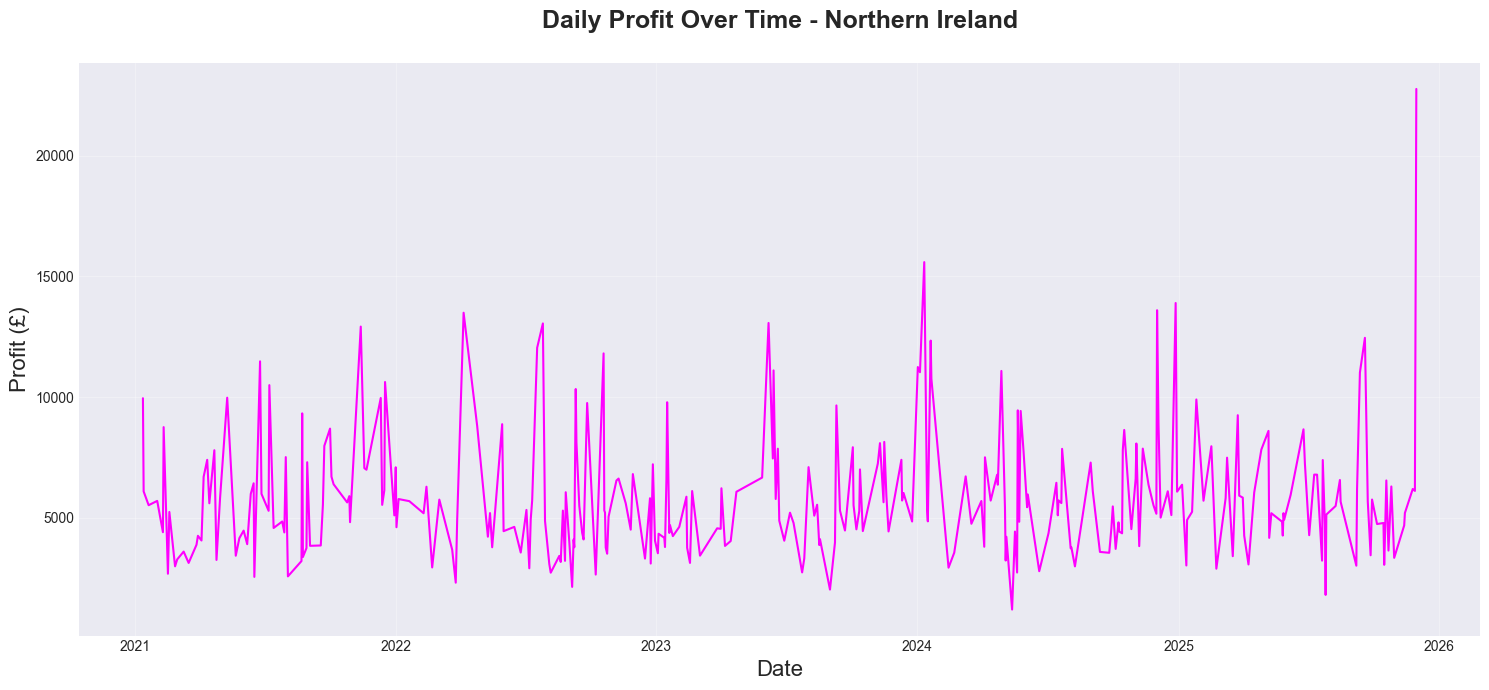

In [72]:
# Daily profit time-series plot
# building daily time-series dataset
daily_country = (changed_df.groupby(["Date", "Country"])[["Units Sold", "Revenue(£)", "Profit(£)"]].sum().reset_index())

# plotting daily profit trends per region
countries = daily_country["Country"].unique()

for country in countries: 
    subset = daily_country[daily_country["Country"] == country]
    plt.figure(figsize = (15, 7))
    plt.plot(subset["Date"], subset["Profit(£)"], color = "fuchsia", linewidth= 1.5)
    plt.title(f"Daily Profit Over Time - {country}\n", fontsize=18, fontweight="bold")
    plt.xlabel("Date", fontsize= 16)
    plt.ylabel("Profit (£)", fontsize= 16)
    plt.grid(alpha=0.3)
    plt.tight_layout()
    plt.show()

Monthly Aggregated Data:

    Country  Month  Profit(£)
0   England      1    5504.65
1   England      2    5182.12
2   England      3    4972.75
3   England      4    6772.55
4   England      5    4973.46
5   England      6    4602.78
6   England      7    5022.59
7   England      8    5242.96
8   England      9    5090.60
9   England     10    5381.69
10  England     11    7632.37
11  England     12    7127.24
12  Ireland      1    5834.62
13  Ireland      2    5681.63
14  Ireland      3    5034.27


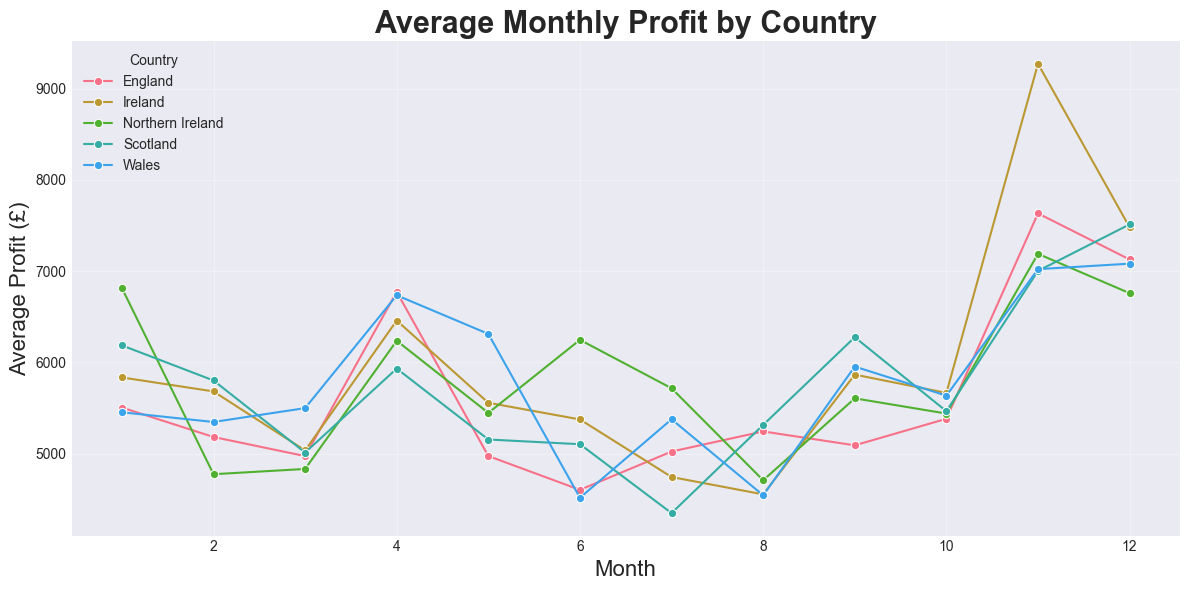

In [73]:
# Monthly seasonality for each region
# Extracting month from the date
daily_country["Month"] = daily_country["Date"].dt.month

# calculating average monthly profit per country
monthly_profit = (daily_country.groupby(["Country", "Month"])["Profit(£)"].mean().reset_index())

print("Monthly Aggregated Data:\n")
print(monthly_profit.head(15))

# Plotting monthly seasonality for all regions

plt.figure(figsize=(12, 6))
sns.lineplot(
    data=monthly_profit,
    x="Month",
    y= "Profit(£)",
    hue="Country",
    marker="o"
)

plt.title("Average Monthly Profit by Country", fontsize=22, fontweight="bold")
plt.xlabel("Month", fontsize=16)
plt.ylabel("Average Profit (£)", fontsize=16)
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

Profit by Day of Week:

           Total_Profit  Average_Profit  Transaction_Count
DayName                                                   
Monday       1501843.63         5108.31                294
Tuesday      1312425.07         5270.78                249
Wednesday    1336015.88         5118.83                261
Thursday     1333477.21         5070.26                263
Friday       1431804.64         5244.71                273
Saturday     1470215.24         5232.08                281
Sunday       1465451.63         5233.76                280


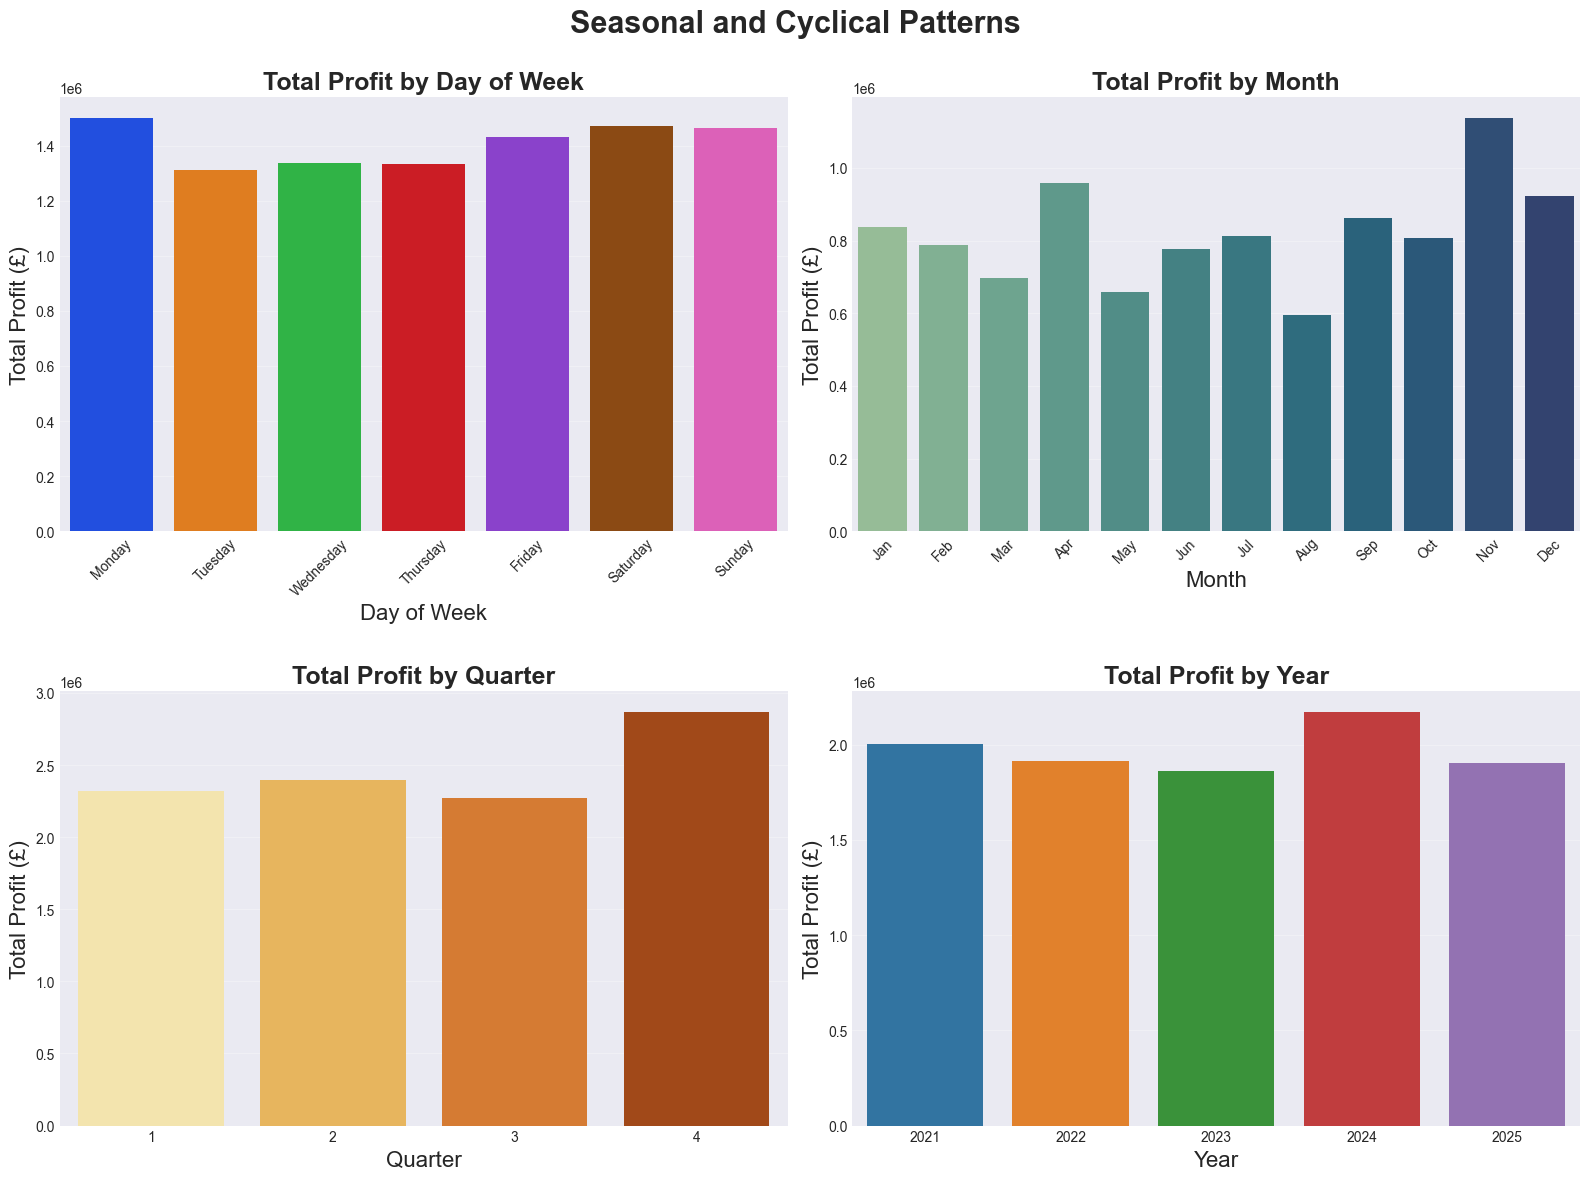

In [74]:
# Extract temporal features
changed_df['Year'] = changed_df['Date'].dt.year
changed_df['DayOfWeek'] = changed_df['Date'].dt.dayofweek
changed_df['DayName'] = changed_df['Date'].dt.day_name()
changed_df['Quarter'] = changed_df['Date'].dt.quarter

# Profit by Day of Week
day_profit = (changed_df.groupby('DayName')['Profit(£)']
              .agg(Total_Profit='sum', Average_Profit='mean', Transaction_Count='count')
              .reindex(['Monday', 'Tuesday', 'Wednesday', 'Thursday', 'Friday', 'Saturday', 'Sunday']))

print("Profit by Day of Week:\n")
print(day_profit)

# Prepare figure
fig, axes = plt.subplots(2, 2, figsize=(16, 12))
fig.suptitle('Seasonal and Cyclical Patterns', fontsize=22, fontweight='bold')

# Profit by Day of Week 
sns.barplot(
    x=day_profit.index,
    y=day_profit['Total_Profit'],
    ax=axes[0, 0],
    palette=sns.color_palette('bright', 7)
)
axes[0, 0].set_title('\nTotal Profit by Day of Week', fontweight='bold', fontsize=18)
axes[0, 0].set_xlabel('Day of Week', fontsize=16)
axes[0, 0].set_ylabel('Total Profit (£)', fontsize=16)
axes[0, 0].tick_params(axis='x', rotation=45)
axes[0, 0].grid(axis='y', alpha=0.3)

# Profit by Month
month_profit = daily_country.groupby('Month')['Profit(£)'].sum()
month_names = ['Jan', 'Feb', 'Mar', 'Apr', 'May', 'Jun',
               'Jul', 'Aug', 'Sep', 'Oct', 'Nov', 'Dec']

sns.barplot(
    x=month_names,
    y=month_profit.values,
    ax=axes[0, 1],
    palette=sns.color_palette('crest', 12)
)
axes[0, 1].set_title('\nTotal Profit by Month', fontweight='bold', fontsize=18)
axes[0, 1].set_xlabel('Month', fontsize=16)
axes[0, 1].set_ylabel('Total Profit (£)', fontsize=16)
axes[0, 1].tick_params(axis='x', rotation=45)
axes[0, 1].grid(axis='y', alpha=0.3)

# Profit by Quarter
quarter_profit = (
    changed_df
    .groupby('Quarter')['Profit(£)']
    .agg(Total_Profit='sum', Average_Profit='mean')
)

sns.barplot(
    x=quarter_profit.index,
    y=quarter_profit['Total_Profit'],
    ax=axes[1, 0],
    palette=sns.color_palette('YlOrBr', 4)
)
axes[1, 0].set_title('\nTotal Profit by Quarter', fontweight='bold', fontsize=18)
axes[1, 0].set_xlabel('Quarter', fontsize=16)
axes[1, 0].set_ylabel('Total Profit (£)', fontsize=16)
axes[1, 0].grid(axis='y', alpha=0.3)

# Profit by Year
year_profit = changed_df.groupby('Year')['Profit(£)'].sum()

sns.barplot(
    x=year_profit.index,
    y=year_profit.values,
    ax=axes[1, 1],
    palette=sns.color_palette('tab10', len(year_profit))
)
axes[1, 1].set_title('\nTotal Profit by Year', fontweight='bold', fontsize=18)
axes[1, 1].set_xlabel('Year', fontsize=16)
axes[1, 1].set_ylabel('Total Profit (£)', fontsize=16)
axes[1, 1].grid(axis='y', alpha=0.3)

plt.tight_layout()
plt.show()


### 5:3 Correlation Analysis

Correlation Matrix:

            Revenue(£)  Cost(£)  Profit(£)
Revenue(£)        1.00     0.95       0.95
Cost(£)           0.95     1.00       0.81
Profit(£)         0.95     0.81       1.00


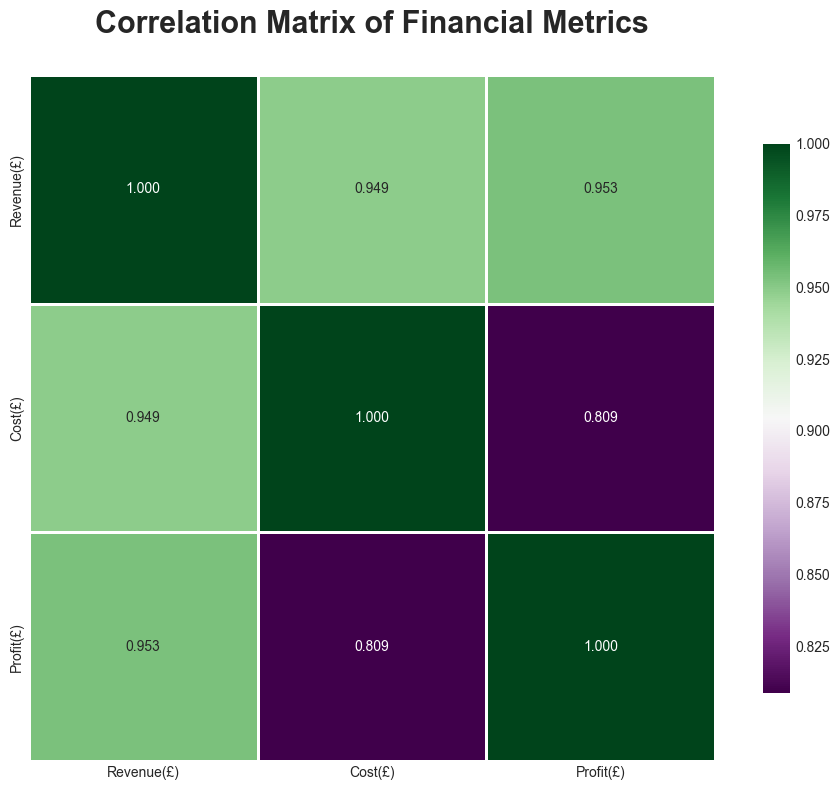

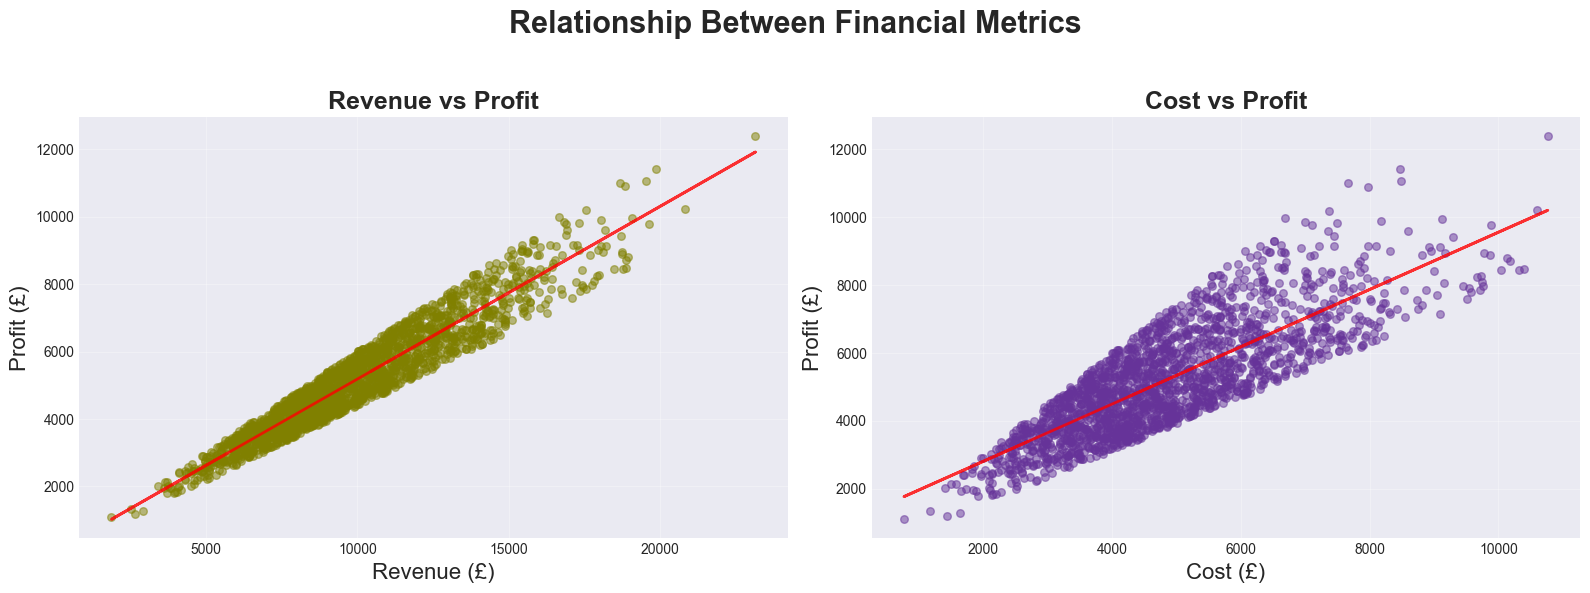

In [75]:
# Correlation Matrix
numerical_features = ['Revenue(£)', 'Cost(£)', 'Profit(£)']
corr_matrix = changed_df[numerical_features].corr()

print("Correlation Matrix:\n")
print(corr_matrix)

# Heatmap
plt.figure(figsize=(10, 8))
sns.heatmap(
    corr_matrix,
    annot=True,
    fmt='.3f',
    cmap='PRGn',
    square=True,
    linewidths=1,
    cbar_kws={"shrink": 0.8}
)
plt.title('Correlation Matrix of Financial Metrics\n', fontsize=22, fontweight='bold')
plt.tight_layout()
plt.show()

# Scatter Plots with Regression Lines
fig, axes = plt.subplots(1, 2, figsize=(16, 6))
fig.suptitle('Relationship Between Financial Metrics\n', fontsize=22, fontweight='bold')

# Helper function for scatter + regression
def scatter_with_reg(ax, x, y, xlabel, ylabel, title, color='Olive'):
    ax.scatter(x, y, alpha=0.5, s=30, color=color)
    ax.set_xlabel(xlabel, fontsize=16)
    ax.set_ylabel(ylabel, fontsize=16)
    ax.set_title(title, fontweight='bold', fontsize=18)
    ax.grid(alpha=0.3)

    # Regression line
    z = np.polyfit(x, y, 1)
    p = np.poly1d(z)
    ax.plot(x, p(x), "r-", linewidth=2, alpha=0.8)

# Revenue vs Profit
scatter_with_reg(
    axes[0],
    changed_df['Revenue(£)'],
    changed_df['Profit(£)'],
    'Revenue (£)',
    'Profit (£)',
    'Revenue vs Profit'
)

# Cost vs Profit
scatter_with_reg(
    axes[1],
    changed_df['Cost(£)'],
    changed_df['Profit(£)'],
    'Cost (£)',
    'Profit (£)',
    'Cost vs Profit',
    color='RebeccaPurple'
)

plt.tight_layout()
plt.show()


## Step 6: Feature Engineering

In [76]:
# Prepare daily aggregated dataset
ts_data = (changed_df.groupby('Date').agg(Profit=('Profit(£)', 'sum'),Revenue=('Revenue(£)', 'sum'),Cost=('Cost(£)', 'sum')).sort_index())

# Create complete date range 
full_range = pd.date_range(ts_data.index.min(), ts_data.index.max(), freq='D') 
ts_data = ts_data.reindex(full_range, fill_value=0) 
ts_data.index.name = 'Date'

# Display message
print(f"Time series data shape: {ts_data.shape}")
print(f"Date range: {ts_data.index.min().date()} to {ts_data.index.max().date()}\n")
print("First few rows:\n")
print(ts_data.head(10))


Time series data shape: (1825, 3)
Date range: 2021-01-01 to 2025-12-30

First few rows:

             Profit  Revenue     Cost
Date                                 
2021-01-01  2973.08  5678.20  2705.12
2021-01-02     0.00     0.00     0.00
2021-01-03 12672.54 26085.31 13412.77
2021-01-04     0.00     0.00     0.00
2021-01-05 11662.70 20935.18  9272.48
2021-01-06     0.00     0.00     0.00
2021-01-07  3324.88  6027.84  2702.96
2021-01-08 12468.44 21644.86  9176.42
2021-01-09  6714.09 12290.94  5576.85
2021-01-10  3950.16  8099.64  4149.48


In [77]:
def create_time_features(df):
    df = df.copy()
    idx = df.index  

    # Basic date components
    df['Year'] = idx.year
    df['Month'] = idx.month
    df['Day'] = idx.day
    df['DayOfWeek'] = idx.weekday
    df['DayOfYear'] = idx.dayofyear
    df['Quarter'] = idx.quarter
    df['WeekOfYear'] = idx.isocalendar().week.astype(int)

    # Binary flags
    df['IsWeekend'] = (idx.weekday >= 5).astype(int)
    df['IsMonthStart'] = idx.is_month_start.astype(int)
    df['IsMonthEnd'] = idx.is_month_end.astype(int)
    df['IsQuarterStart'] = idx.is_quarter_start.astype(int)
    df['IsQuarterEnd'] = idx.is_quarter_end.astype(int)

    # Cyclical encodings
    df[['Month_Sin', 'Month_Cos']] = np.column_stack([np.sin(2 * np.pi * idx.month / 12),np.cos(2 * np.pi * idx.month / 12)])

    df[['DayOfWeek_Sin', 'DayOfWeek_Cos']] = np.column_stack([np.sin(2 * np.pi * idx.weekday / 7),np.cos(2 * np.pi * idx.weekday / 7)])

    # Trend feature
    df['Days_Since_Start'] = (idx - idx.min()).days

    return df


# Apply feature engineering
ts_features = create_time_features(ts_data)

print("Created temporal features:")
print(ts_features.columns.tolist())
print("\nSample of feature-engineered data:")
print(ts_features.head(10))


Created temporal features:
['Profit', 'Revenue', 'Cost', 'Year', 'Month', 'Day', 'DayOfWeek', 'DayOfYear', 'Quarter', 'WeekOfYear', 'IsWeekend', 'IsMonthStart', 'IsMonthEnd', 'IsQuarterStart', 'IsQuarterEnd', 'Month_Sin', 'Month_Cos', 'DayOfWeek_Sin', 'DayOfWeek_Cos', 'Days_Since_Start']

Sample of feature-engineered data:
             Profit  Revenue     Cost  Year  Month  Day  DayOfWeek  DayOfYear  \
Date                                                                            
2021-01-01  2973.08  5678.20  2705.12  2021      1    1          4          1   
2021-01-02     0.00     0.00     0.00  2021      1    2          5          2   
2021-01-03 12672.54 26085.31 13412.77  2021      1    3          6          3   
2021-01-04     0.00     0.00     0.00  2021      1    4          0          4   
2021-01-05 11662.70 20935.18  9272.48  2021      1    5          1          5   
2021-01-06     0.00     0.00     0.00  2021      1    6          2          6   
2021-01-07  3324.88  6027.8

In [78]:
def create_lag_features(df, target_col='Profit', lags=None):
    df = df.copy()
    if lags is None:
        lags = [1, 7, 14, 30]

    # Lag features
    for lag in lags:
        df[f'{target_col}_Lag_{lag}'] = df[target_col].shift(lag)

    # Rolling window features
    windows = [7, 14, 30]
    for w in windows:
        roll = df[target_col].rolling(w)
        df[f'{target_col}_Rolling_Mean_{w}'] = roll.mean()
        df[f'{target_col}_Rolling_Std_{w}'] = roll.std()
        df[f'{target_col}_Rolling_Min_{w}'] = roll.min()
        df[f'{target_col}_Rolling_Max_{w}'] = roll.max()

    # Exponential weighted moving averages
    exp_weigh_mov_avg = {7: 'exp_weigh_mov_7', 30: 'exp_weigh_mov_30'}
    for span, name in exp_weigh_mov_avg.items():
        df[f'{target_col}_{name}'] = df[target_col].ewm(span=span, adjust=False).mean()

    # Percentage change features
    for p in [1, 7]:
        df[f'{target_col}_Pct_Change_{p}'] = df[target_col].pct_change(p)

    return df


# Apply lag features
ts_features = create_lag_features(ts_features)

print("Total features after lag creation:")
print(f"Number of features: {ts_features.shape[1]}")
print("\nFeature list:")
print(ts_features.columns.tolist())


Total features after lag creation:
Number of features: 40

Feature list:
['Profit', 'Revenue', 'Cost', 'Year', 'Month', 'Day', 'DayOfWeek', 'DayOfYear', 'Quarter', 'WeekOfYear', 'IsWeekend', 'IsMonthStart', 'IsMonthEnd', 'IsQuarterStart', 'IsQuarterEnd', 'Month_Sin', 'Month_Cos', 'DayOfWeek_Sin', 'DayOfWeek_Cos', 'Days_Since_Start', 'Profit_Lag_1', 'Profit_Lag_7', 'Profit_Lag_14', 'Profit_Lag_30', 'Profit_Rolling_Mean_7', 'Profit_Rolling_Std_7', 'Profit_Rolling_Min_7', 'Profit_Rolling_Max_7', 'Profit_Rolling_Mean_14', 'Profit_Rolling_Std_14', 'Profit_Rolling_Min_14', 'Profit_Rolling_Max_14', 'Profit_Rolling_Mean_30', 'Profit_Rolling_Std_30', 'Profit_Rolling_Min_30', 'Profit_Rolling_Max_30', 'Profit_exp_weigh_mov_7', 'Profit_exp_weigh_mov_30', 'Profit_Pct_Change_1', 'Profit_Pct_Change_7']


In [79]:
# Remove rows with NaN values created by lag features
before = len(ts_features)
ts_features_clean = ts_features.dropna()
after = len(ts_features_clean)

print(f"Rows before dropping NaN: {before}")
print(f"Rows after dropping NaN: {after}")
print(f"Rows removed: {before - after}\n")

print("Final dataset for modelling:")
print(ts_features_clean.head(10))

Rows before dropping NaN: 1825
Rows after dropping NaN: 1414
Rows removed: 411

Final dataset for modelling:
             Profit  Revenue     Cost  Year  Month  Day  DayOfWeek  DayOfYear  \
Date                                                                            
2021-01-31  9802.61 18944.52  9141.91  2021      1   31          6         31   
2021-02-01 20872.77 37098.82 16226.05  2021      2    1          0         32   
2021-02-02     0.00     0.00     0.00  2021      2    2          1         33   
2021-02-05  4961.90  9496.05  4534.15  2021      2    5          4         36   
2021-02-06 19458.12 35064.72 15606.60  2021      2    6          5         37   
2021-02-07     0.00     0.00     0.00  2021      2    7          6         38   
2021-02-09  7953.92 15804.79  7850.87  2021      2    9          1         40   
2021-02-10  8756.31 15653.88  6897.57  2021      2   10          2         41   
2021-02-11  3420.89  7354.16  3933.27  2021      2   11          3         42   


## Step 7: Model Preparation

### 7:1 Train-test Split

In [80]:
# Define target
target = 'Profit'

# Drop target + related columns to form X
X = ts_features_clean.drop(columns=['Profit', 'Revenue', 'Cost'])

# Target vector
y = ts_features_clean[target]

# Display message
print(f"Features shape: {X.shape}")
print(f"Target shape: {y.shape}\n")

print(f"Features used: {X.shape[1]}")
print(list(X.columns))


Features shape: (1414, 37)
Target shape: (1414,)

Features used: 37
['Year', 'Month', 'Day', 'DayOfWeek', 'DayOfYear', 'Quarter', 'WeekOfYear', 'IsWeekend', 'IsMonthStart', 'IsMonthEnd', 'IsQuarterStart', 'IsQuarterEnd', 'Month_Sin', 'Month_Cos', 'DayOfWeek_Sin', 'DayOfWeek_Cos', 'Days_Since_Start', 'Profit_Lag_1', 'Profit_Lag_7', 'Profit_Lag_14', 'Profit_Lag_30', 'Profit_Rolling_Mean_7', 'Profit_Rolling_Std_7', 'Profit_Rolling_Min_7', 'Profit_Rolling_Max_7', 'Profit_Rolling_Mean_14', 'Profit_Rolling_Std_14', 'Profit_Rolling_Min_14', 'Profit_Rolling_Max_14', 'Profit_Rolling_Mean_30', 'Profit_Rolling_Std_30', 'Profit_Rolling_Min_30', 'Profit_Rolling_Max_30', 'Profit_exp_weigh_mov_7', 'Profit_exp_weigh_mov_30', 'Profit_Pct_Change_1', 'Profit_Pct_Change_7']


In [81]:
# Temporal 80/20 split using index slicing
n_train = int(0.8 * len(X))

train_idx = X.index[:n_train]
test_idx = X.index[n_train:]

X_train = X.loc[train_idx]
X_test = X.loc[test_idx]

y_train = y.loc[train_idx]
y_test = y.loc[test_idx]

# Display message
train_pct = (len(X_train) / len(X)) * 100
test_pct = (len(X_test) / len(X)) * 100

print("Train-Test Split:")
print(f"Training set: {len(X_train)} samples ({train_pct:.1f}%)")
print(f"Test set: {len(X_test)} samples ({test_pct:.1f}%)\n")

print(f"Training period: {train_idx.min().date()} to {train_idx.max().date()}")
print(f"Test period: {test_idx.min().date()} to {test_idx.max().date()}")


Train-Test Split:
Training set: 1131 samples (80.0%)
Test set: 283 samples (20.0%)

Training period: 2021-01-31 to 2024-12-20
Test period: 2024-12-21 to 2025-12-30


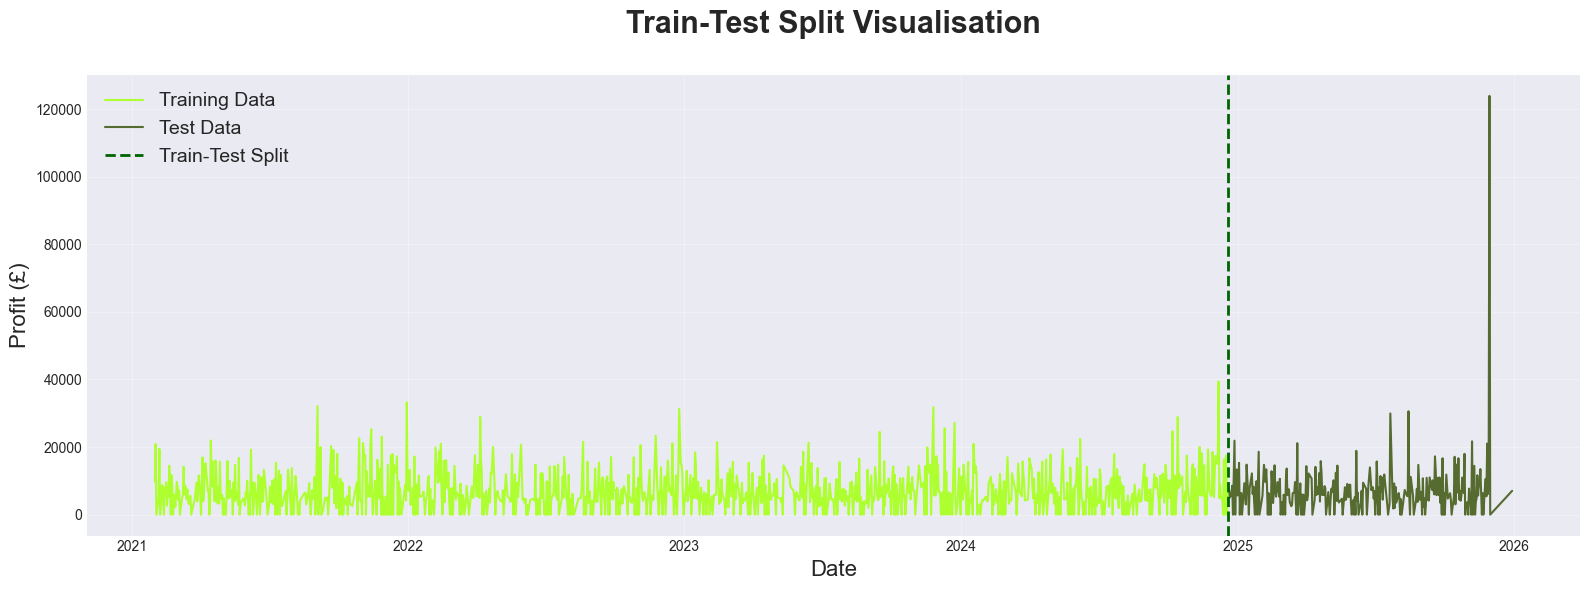

In [82]:
# Visualise train-test split
plt.figure(figsize=(16, 6))

# Plot training and test series
plt.plot(y_train.index, y_train, color='GreenYellow', linewidth=1.5, label='Training Data')
plt.plot(y_test.index, y_test, color='DarkOliveGreen', linewidth=1.5, label='Test Data')

# Vertical split marker
split_point = y_train.index.max()
plt.axvline(split_point, color='DarkGreen', linestyle='--', linewidth=2, label='Train-Test Split')

# Titles and labels
plt.title('Train-Test Split Visualisation\n', fontsize=22, fontweight='bold')
plt.xlabel('Date', fontsize=16)
plt.ylabel('Profit (£)', fontsize=16)

# Legend and grid
plt.legend(fontsize=14)
plt.grid(alpha=0.3)

plt.tight_layout()
plt.show()


### 7:2 Feature Scaling

In [83]:
# Clean training and test features
# Replace inf values with NaN
X_train = X_train.replace([np.inf, -np.inf], np.nan)
X_test = X_test.replace([np.inf, -np.inf], np.nan)

# Fill missing values using forward/backward fill
X_train = X_train.ffill().bfill()
X_test = X_test.ffill().bfill()

# Final fallback: fill any remaining NaNs with column means (from training set)
train_means = X_train.mean()
X_train = X_train.fillna(train_means)
X_test = X_test.fillna(train_means)

# Summary of cleaning
print("Data cleaning complete!")
print(f"Any NaN values in X_train: {X_train.isna().sum().sum()}")
print(f"Any infinite values in X_train: {np.isinf(X_train).sum().sum()}")

# Standardise features
scaler = StandardScaler()

X_train_scaled = pd.DataFrame(
    scaler.fit_transform(X_train),
    index=X_train.index,
    columns=X_train.columns
)

X_test_scaled = pd.DataFrame(
    scaler.transform(X_test),
    index=X_test.index,
    columns=X_test.columns
)

# Display message of scaling
print("Features scaled successfully!")
print(f"\nScaled training features shape: {X_train_scaled.shape}")
print(f"Scaled test features shape: {X_test_scaled.shape}")
print("\nSample of scaled features:")
print(X_train_scaled.head())


Data cleaning complete!
Any NaN values in X_train: 0
Any infinite values in X_train: 0
Features scaled successfully!

Scaled training features shape: (1131, 37)
Scaled test features shape: (283, 37)

Sample of scaled features:
            Year  Month   Day  DayOfWeek  DayOfYear  Quarter  WeekOfYear  \
Date                                                                       
2021-01-31 -1.37  -1.65  1.74       1.51      -1.49    -1.40       -1.55   
2021-02-01 -1.37  -1.36 -1.61      -1.50      -1.48    -1.40       -1.48   
2021-02-02 -1.37  -1.36 -1.50      -1.00      -1.47    -1.40       -1.48   
2021-02-05 -1.37  -1.36 -1.17       0.51      -1.44    -1.40       -1.48   
2021-02-06 -1.37  -1.36 -1.05       1.01      -1.43    -1.40       -1.48   

            IsWeekend  IsMonthStart  IsMonthEnd  IsQuarterStart  IsQuarterEnd  \
Date                                                                            
2021-01-31       1.59         -0.19        5.29           -0.11         -0.09 

## Step 8: Model Building and Evaluation

### 8:1 Linear Regression

In [84]:
# Train Linear Regression Model
lr = LinearRegression()
lr.fit(X_train_scaled, y_train)

# Generate predictions
lr_train_pred = lr.predict(X_train_scaled)
lr_test_pred = lr.predict(X_test_scaled)

# Compute metrics
metrics = {
    "lr_train_rmse": np.sqrt(mean_squared_error(y_train, lr_train_pred)),
    "lr_test_rmse": np.sqrt(mean_squared_error(y_test, lr_test_pred)),
    "lr_train_mae": mean_absolute_error(y_train, lr_train_pred),
    "lr_test_mae": mean_absolute_error(y_test, lr_test_pred),
    "lr_train_r2": r2_score(y_train, lr_train_pred),
    "lr_test_r2": r2_score(y_test, lr_test_pred)
}

# Display message
print("Linear Regression Results:")
print("*" * 30)
print(f"Training RMSE: £{metrics['lr_train_rmse']:.2f}")
print(f"Test RMSE: £{metrics['lr_test_rmse']:.2f}")
print(f"Training MAE: £{metrics['lr_train_mae']:.2f}")
print(f"Test MAE: £{metrics['lr_test_mae']:.2f}")
print(f"Training R²: {metrics['lr_train_r2']:.4f}")
print(f"Test R²: {metrics['lr_test_r2']:.4f}")


Linear Regression Results:
******************************
Training RMSE: £2101.24
Test RMSE: £2531.29
Training MAE: £1635.39
Test MAE: £1598.54
Training R²: 0.8640
Test R²: 0.9149



Top 15 Most Important Features (Linear Regression):
                         Coefficient
Profit_exp_weigh_mov_7       9695.96
DayOfYear                    4970.97
Month                       -4484.07
Profit_Rolling_Mean_7       -3896.44
Profit_exp_weigh_mov_30     -2913.52
Profit_Lag_1                -2743.59
Profit_Rolling_Mean_30       1369.85
WeekOfYear                  -1134.56
Profit_Pct_Change_7           837.97
Profit_Rolling_Mean_14       -764.58
Profit_Rolling_Std_7          687.18
Quarter                       672.77
Days_Since_Start              666.58
Profit_Rolling_Max_7         -633.96
Year                         -586.16


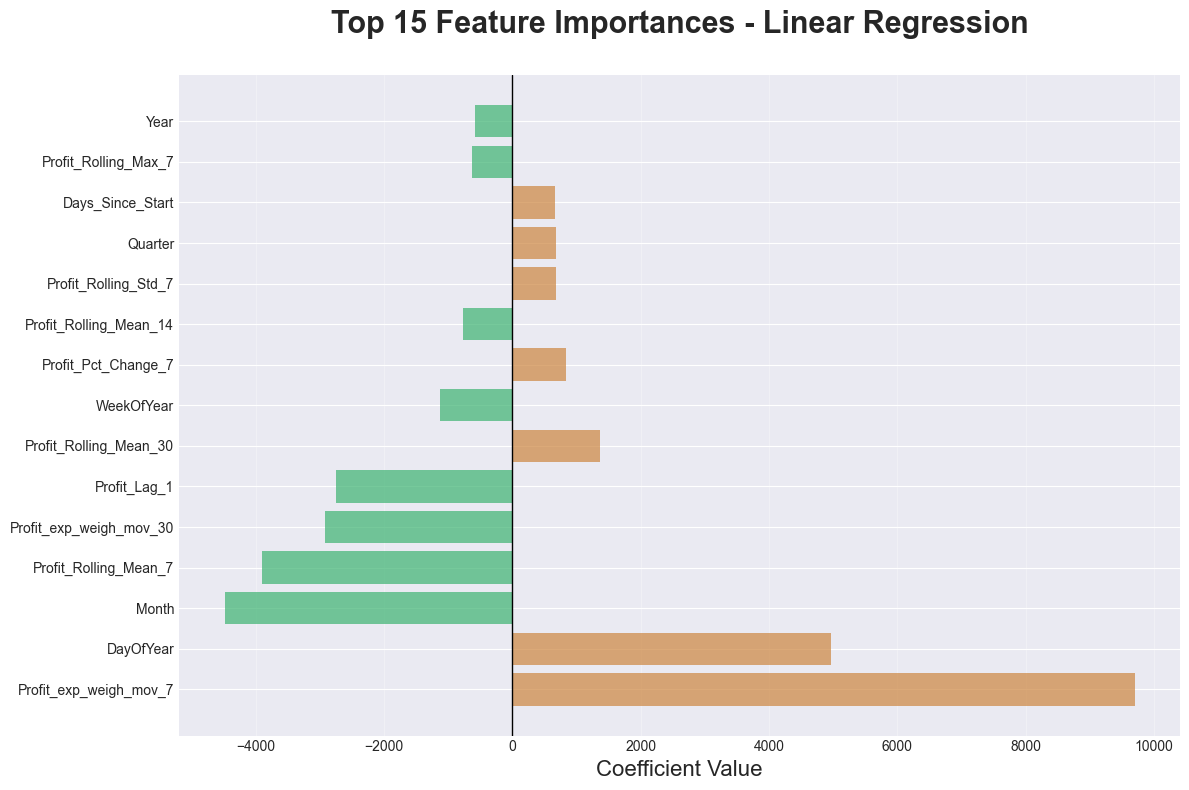

In [85]:
# Compute feature importance for Linear Regression
coeffs = pd.Series(lr.coef_, index=X_train.columns)
feature_importance_lr = coeffs.abs().sort_values(ascending=False).to_frame(name='Coefficient')
feature_importance_lr['Coefficient'] = coeffs[feature_importance_lr.index]

print("\nTop 15 Most Important Features (Linear Regression):")
print(feature_importance_lr.head(15))

# Visualise top features
top15 = feature_importance_lr.head(15)

plt.figure(figsize=(12, 8))
colors = ['Peru' if val > 0 else 'MediumSeaGreen' for val in top15['Coefficient']]

plt.barh(top15.index, top15['Coefficient'], color=colors, alpha=0.7)
plt.axvline(0, color='black', linewidth=1)
plt.title('Top 15 Feature Importances - Linear Regression\n', fontsize=22, fontweight='bold')
plt.xlabel('Coefficient Value', fontsize=16)
plt.grid(axis='x', alpha=0.3)

plt.tight_layout()
plt.show()

### 8:2 Ridge Regression

In [86]:
# Train Ridge Regression Model
rr = Ridge(alpha=1.0)
rr.fit(X_train_scaled, y_train)

# Predictions
rr_train = rr.predict(X_train_scaled)
rr_test = rr.predict(X_test_scaled)

# Evaluation metrics
ridge_metrics = {
    "rr_rmse_train": np.sqrt(mean_squared_error(y_train, rr_train)),
    "rr_rmse_test": np.sqrt(mean_squared_error(y_test, rr_test)),
    "rr_mae_train": mean_absolute_error(y_train, rr_train),
    "rr_mae_test": mean_absolute_error(y_test, rr_test),
    "rr_r2_train": r2_score(y_train, rr_train),
    "rr_r2_test": r2_score(y_test, rr_test)
}

# Display message
print("Ridge Regression Results:")
print("*" * 25)
print(f"Training RMSE: £{ridge_metrics['rr_rmse_train']:.2f}")
print(f"Test RMSE: £{ridge_metrics['rr_rmse_test']:.2f}")
print(f"Training MAE: £{ridge_metrics['rr_mae_train']:.2f}")
print(f"Test MAE: £{ridge_metrics['rr_mae_test']:.2f}")
print(f"Training R²: {ridge_metrics['rr_r2_train']:.4f}")
print(f"Test R²: {ridge_metrics['rr_r2_test']:.4f}")


Ridge Regression Results:
*************************
Training RMSE: £2101.85
Test RMSE: £2549.53
Training MAE: £1634.16
Test MAE: £1595.73
Training R²: 0.8639
Test R²: 0.9136


### 8:3 Lasso Regression

In [87]:
# Train Lasso Regression Model
lasso = Lasso(alpha=1.0)
lasso.fit(X_train_scaled, y_train)

# Predictions
lsr_train = lasso.predict(X_train_scaled)
lsr_test = lasso.predict(X_test_scaled)

# Evaluation metrics
lasso_scores = {
    "lsr_rmse_train": np.sqrt(mean_squared_error(y_train, lsr_train)),
    "lsr_rmse_test": np.sqrt(mean_squared_error(y_test, lsr_test)),
    "lsr_mae_train": mean_absolute_error(y_train, lsr_train),
    "lsr_mae_test": mean_absolute_error(y_test, lsr_test),
    "lsr_r2_train": r2_score(y_train, lsr_train),
    "lsr_r2_test": r2_score(y_test, lsr_test)
}

# Display message
print("Lasso Regression Results:")
print("*" * 25)
print(f"Training RMSE: £{lasso_scores['lsr_rmse_train']:.2f}")
print(f"Test RMSE: £{lasso_scores['lsr_rmse_test']:.2f}")
print(f"Training MAE: £{lasso_scores['lsr_mae_train']:.2f}")
print(f"Test MAE: £{lasso_scores['lsr_mae_test']:.2f}")
print(f"Training R²: {lasso_scores['lsr_r2_train']:.4f}")
print(f"Test R²: {lasso_scores['lsr_r2_test']:.4f}")

# Feature selection (non-zero coefficients)
nonzero_mask = lasso.coef_ != 0
selected_features = X_train.columns[nonzero_mask]

print(f"\nNumber of features selected by Lasso: {nonzero_mask.sum()} out of {X_train.shape[1]}")
print(f"Features eliminated: {X_train.shape[1] - nonzero_mask.sum()}")


Lasso Regression Results:
*************************
Training RMSE: £2101.47
Test RMSE: £2531.63
Training MAE: £1635.37
Test MAE: £1595.41
Training R²: 0.8639
Test R²: 0.9149

Number of features selected by Lasso: 34 out of 37
Features eliminated: 3


### 8:4 Polynomial Regression

In [88]:
# Select top N important features
top_n = 10
top_features = feature_importance_lr.index[:top_n].tolist()

Xtr_sub = X_train[top_features]
Xte_sub = X_test[top_features]

# Polynomial feature expansion
poly = PolynomialFeatures(degree=2, include_bias=False)
X_train_poly = poly.fit_transform(Xtr_sub)
X_test_poly = poly.transform(Xte_sub)

print(f"Original feature count: {Xtr_sub.shape[1]}")
print(f"Polynomial feature count: {X_train_poly.shape[1]}")

# Scale polynomial features
poly_scaler = StandardScaler()
Xtr_poly_scaled = poly_scaler.fit_transform(X_train_poly)
Xte_poly_scaled = poly_scaler.transform(X_test_poly)

# Train polynomial regression model
poly_reg = LinearRegression()
poly_reg.fit(Xtr_poly_scaled, y_train)

# Predictions 
pred_train_poly = poly_reg.predict(Xtr_poly_scaled)
pred_test_poly = poly_reg.predict(Xte_poly_scaled)

# Evaluation metrics
poly_scores = {
    "pr_rmse_train": np.sqrt(mean_squared_error(y_train, pred_train_poly)),
    "pr_rmse_test": np.sqrt(mean_squared_error(y_test, pred_test_poly)),
    "pr_mae_train": mean_absolute_error(y_train, pred_train_poly),
    "pr_mae_test": mean_absolute_error(y_test, pred_test_poly),
    "pr_r2_train": r2_score(y_train, pred_train_poly),
    "pr_r2_test": r2_score(y_test, pred_test_poly)
}

# Display message
print("\nPolynomial Regression Results (Degree 2):")
print("*" * 40)
print(f"Training RMSE: £{poly_scores['pr_rmse_train']:.2f}")
print(f"Test RMSE: £{poly_scores['pr_rmse_test']:.2f}")
print(f"Training MAE: £{poly_scores['pr_mae_train']:.2f}")
print(f"Test MAE: £{poly_scores['pr_mae_test']:.2f}")
print(f"Training R²: {poly_scores['pr_r2_train']:.4f}")
print(f"Test R²: {poly_scores['pr_r2_test']:.4f}")


Original feature count: 10
Polynomial feature count: 65

Polynomial Regression Results (Degree 2):
****************************************
Training RMSE: £2001.44
Test RMSE: £8509.35
Training MAE: £1572.36
Test MAE: £2363.10
Training R²: 0.8766
Test R²: 0.0380


## Step 9: Model Comparison

In [89]:
# Build model comparison table
models = [
    "Linear Regression",
    "Ridge Regression",
    "Lasso Regression",
    "Polynomial Regression"
]

train_rmse_comp = [ metrics["lr_train_rmse"], ridge_metrics["rr_rmse_train"], lasso_scores["lsr_rmse_train"], poly_scores["pr_rmse_train"] ] 
test_rmse_comp = [ metrics["lr_test_rmse"], ridge_metrics["rr_rmse_test"], lasso_scores["lsr_rmse_test"], poly_scores["pr_rmse_test"] ] 
train_mae_comp = [ metrics["lr_train_mae"], ridge_metrics["rr_mae_train"], lasso_scores["lsr_mae_train"], poly_scores["pr_mae_train"] ] 
test_mae_comp = [ metrics["lr_test_mae"], ridge_metrics["rr_mae_test"], lasso_scores["lsr_mae_test"], poly_scores["pr_mae_test"] ] 
train_r2_comp = [ metrics["lr_train_r2"], ridge_metrics["rr_r2_train"], lasso_scores["lsr_r2_train"], poly_scores["pr_r2_train"] ] 
test_r2_comp = [ metrics["lr_test_r2"], ridge_metrics["rr_r2_test"], lasso_scores["lsr_r2_test"], poly_scores["pr_r2_test"] ]

results = pd.DataFrame({
    "Model": models,
    "Train RMSE": train_rmse_comp,                
    "Test RMSE": test_rmse_comp,
    "Train MAE": train_mae_comp,
    "Test MAE": test_mae_comp,
    "Train R²": train_r2_comp,
    "Test R²": test_r2_comp
})

# Display message
print("Model Comparison Summary:")
print("=" * 85)
print(results.to_string(index=False))
print("\n" + "=" * 85)

# Identify best model (lowest Test RMSE)
best_idx = test_rmse_comp.index(min(test_rmse_comp))
best_model = models[best_idx]

print(f"\nBest Model: {best_model}")
print(f"Test RMSE: £{results.loc[best_idx, 'Test RMSE']:.2f}")
print(f"Test R²: {results.loc[best_idx, 'Test R²']:.4f}")


Model Comparison Summary:
                Model  Train RMSE  Test RMSE  Train MAE  Test MAE  Train R²  Test R²
    Linear Regression     2101.24    2531.29    1635.39   1598.54      0.86     0.91
     Ridge Regression     2101.85    2549.53    1634.16   1595.73      0.86     0.91
     Lasso Regression     2101.47    2531.63    1635.37   1595.41      0.86     0.91
Polynomial Regression     2001.44    8509.35    1572.36   2363.10      0.88     0.04


Best Model: Linear Regression
Test RMSE: £2531.29
Test R²: 0.9149


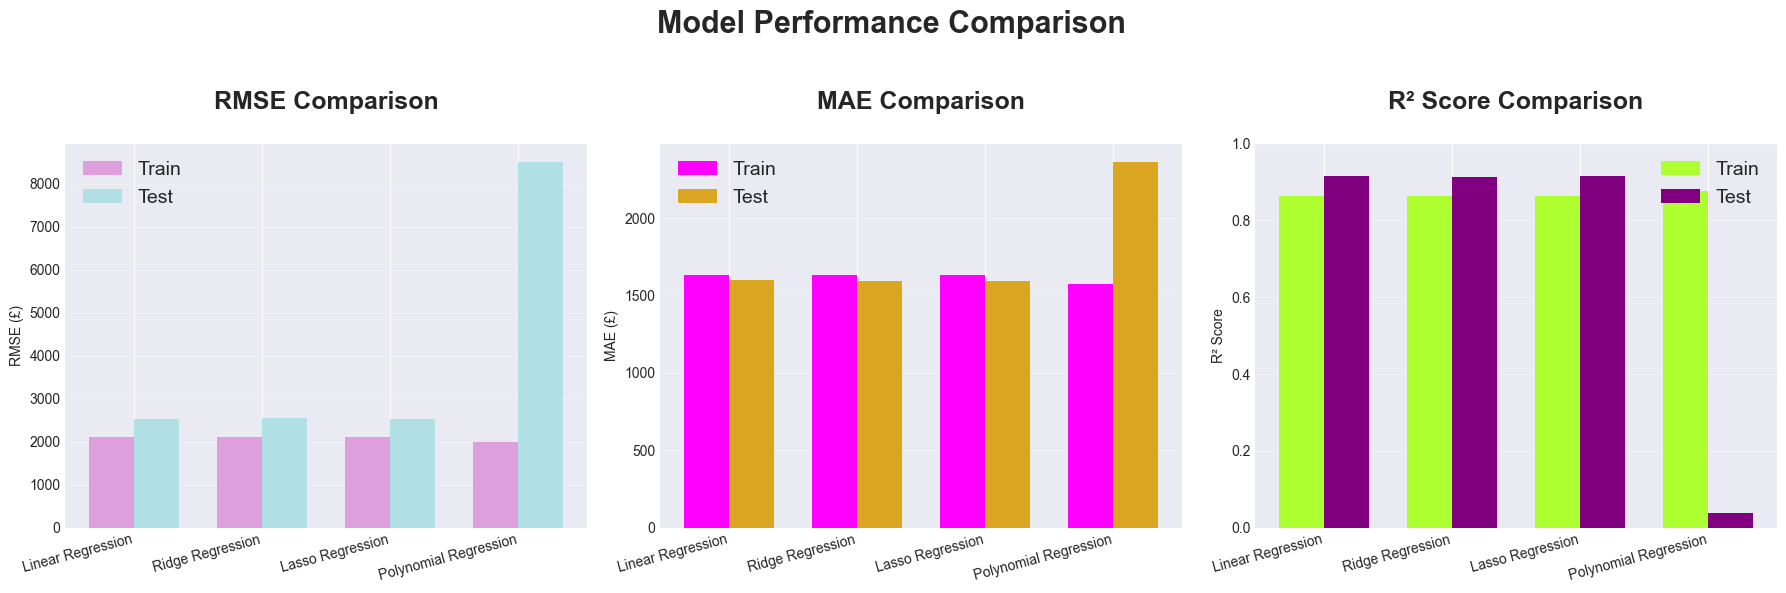

In [90]:
# Visualise model comparison
plt.figure(figsize=(18, 6))
plt.suptitle("Model Performance Comparison\n", fontsize=22, fontweight="bold")

x = np.arange(len(results))
width = 0.35

# RMSE subplot
plt.subplot(1, 3, 1)
plt.bar(x - width/2, results["Train RMSE"], width, color="Plum", label="Train")
plt.bar(x + width/2, results["Test RMSE"], width, color="PowderBlue", label="Test")
plt.title("RMSE Comparison\n", fontweight="bold", fontsize=18)
plt.ylabel("RMSE (£)")
plt.xticks(x, results["Model"], rotation=15, ha="right")
plt.grid(axis="y", alpha=0.3)
plt.legend(fontsize=14)

# MAE subplot
plt.subplot(1, 3, 2)
plt.bar(x - width/2, results["Train MAE"], width, color="Magenta", label="Train")
plt.bar(x + width/2, results["Test MAE"], width, color="GoldenRod", label="Test")
plt.title("MAE Comparison\n", fontweight="bold", fontsize=18)
plt.ylabel("MAE (£)")
plt.xticks(x, results["Model"], rotation=15, ha="right")
plt.grid(axis="y", alpha=0.3)
plt.legend(fontsize=14)

# R² subplot
plt.subplot(1, 3, 3)
plt.bar(x - width/2, results["Train R²"], width, color="GreenYellow", label="Train")
plt.bar(x + width/2, results["Test R²"], width, color="Purple", label="Test")
plt.title("R² Score Comparison\n", fontweight="bold", fontsize=18)
plt.ylabel("R² Score")
plt.xticks(x, results["Model"], rotation=15, ha="right")
plt.grid(axis="y", alpha=0.3)
plt.ylim(0, 1)
plt.legend(fontsize=14)

plt.tight_layout()
plt.show()


## Step 10: Forecast Visualisation

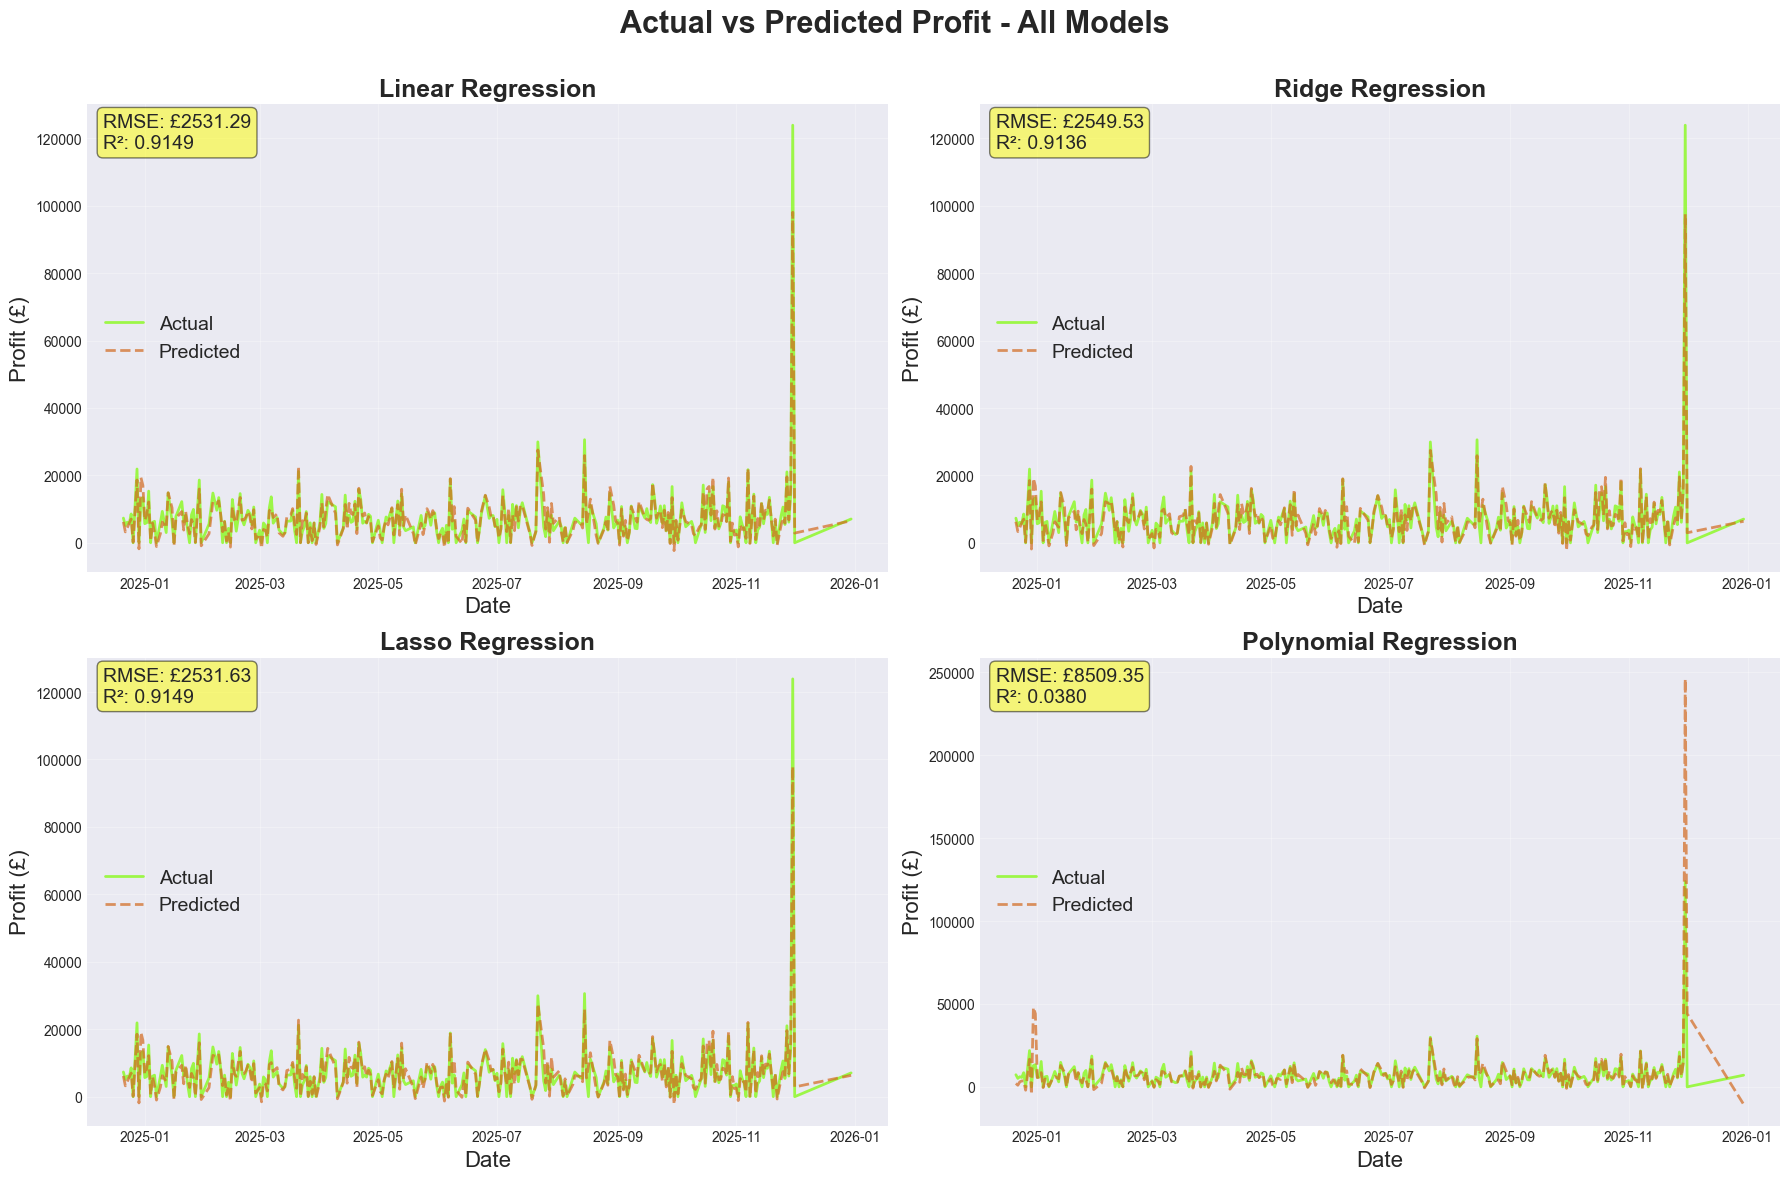

In [91]:
# Visualise predictions for all models
plt.figure(figsize=(18, 12))
plt.suptitle("Actual vs Predicted Profit - All Models\n", fontsize=22, fontweight="bold")

# Prepare model names and predictions
model_names = ["Linear Regression", "Ridge Regression", "Lasso Regression", "Polynomial Regression"]
pred_list = [lr_test_pred, rr_test, lsr_test, pred_test_poly]

# Loop through subplots
for i, (name, preds) in enumerate(zip(model_names, pred_list)):
    plt.subplot(2, 2, i + 1)
    
    # Actual vs Predicted lines
    plt.plot(y_test.index, y_test.values, color="LawnGreen", linewidth=2, alpha=0.7, label="Actual")
    plt.plot(y_test.index, preds, color="Chocolate", linewidth=2, linestyle="--", alpha=0.7, label="Predicted")
    
    # Title and labels
    plt.title(name, fontsize=18, fontweight="bold")
    plt.xlabel("Date", fontsize=16)
    plt.ylabel("Profit (£)", fontsize=16)
    plt.grid(alpha=0.3)
    plt.legend(fontsize=14)
    
    # Add RMSE and R² box
    rmse_val = results.loc[i, "Test RMSE"]
    r2_val = results.loc[i, "Test R²"]
    
    plt.text(
        0.02, 0.98,
        f"RMSE: £{rmse_val:.2f}\nR²: {r2_val:.4f}",
        transform=plt.gca().transAxes,
        fontsize=14,
        verticalalignment="top",
        bbox=dict(boxstyle="round", facecolor="yellow", alpha=0.5)
    )

plt.tight_layout()
plt.show()


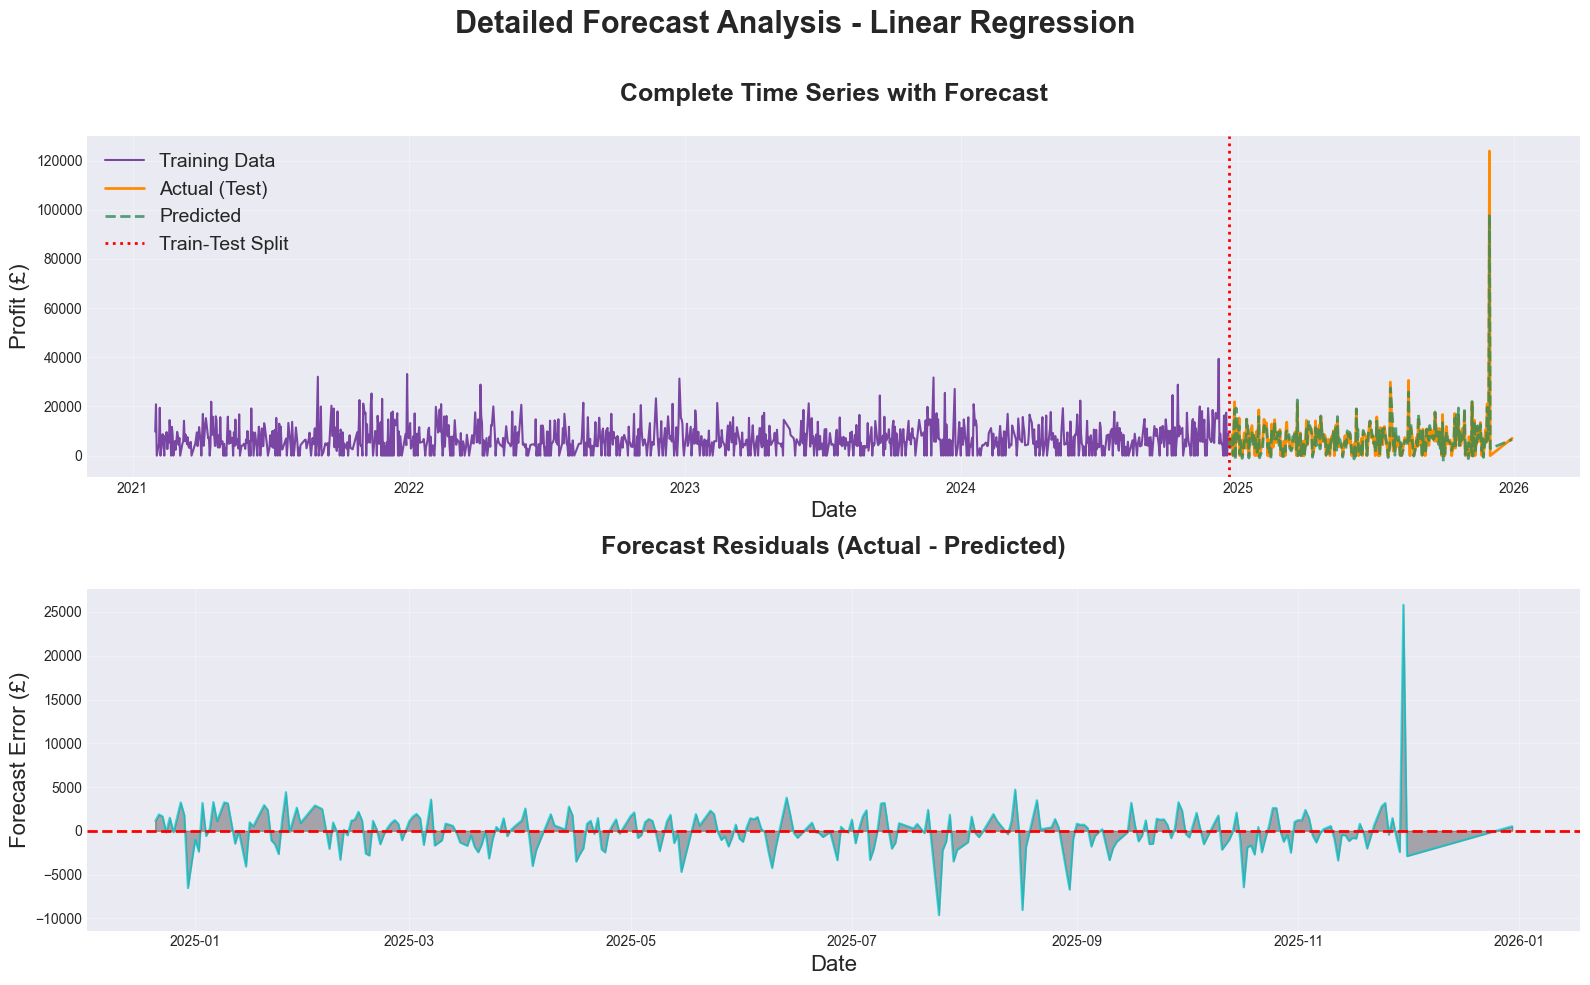


Residual Statistics:
Mean Error: £23.60
Std Dev of Errors: £2531.18
Min Error: £-9619.95
Max Error: £25824.02


In [92]:
# Select predictions from best model
if best_model == 'Linear Regression':
    best_predictions = lr_test_pred
elif best_model == 'Ridge Regression':
    best_predictions = rr_test
elif best_model == 'Lasso Regression':
    best_predictions = lsr_test
else:
    best_predictions = pred_test_poly



# Select predictions for the best model
prediction_map = {
    "Linear Regression": lr_test_pred,
    "Ridge Regression": rr_test,
    "Lasso Regression": lsr_test,
    "Polynomial Regression": pred_test_poly
}

best_predictions = prediction_map[best_model]

# Plotting
plt.figure(figsize=(16, 10))
plt.suptitle(f"Detailed Forecast Analysis - {best_model}\n", fontsize=22, fontweight="bold")

# Full time series
plt.subplot(2, 1, 1)
plt.plot(y_train.index, y_train.values, color="Indigo", linewidth=1.5, alpha=0.7, label="Training Data")
plt.plot(y_test.index, y_test.values, color="DarkOrange", linewidth=2, label="Actual (Test)")
plt.plot(y_test.index, best_predictions, color="SeaGreen", linestyle="--", linewidth=2, alpha=0.8, label="Predicted")
plt.axvline(X_train.index.max(), color="red", linestyle=":", linewidth=2, label="Train-Test Split")
plt.xlabel("Date", fontsize=16)
plt.ylabel("Profit (£)", fontsize=16)
plt.title("Complete Time Series with Forecast\n", fontweight="bold", fontsize=18)
plt.grid(alpha=0.3)
plt.legend(fontsize=14)

# Residuals
residuals = y_test.values - best_predictions

plt.subplot(2, 1, 2)
plt.plot(y_test.index, residuals, color="DarkTurquoise", linewidth=1.5, alpha=0.7)
plt.axhline(0, color="red", linestyle="--", linewidth=2)
plt.fill_between(y_test.index, residuals, 0, color="Black", alpha=0.3)
plt.xlabel("Date", fontsize=16)
plt.ylabel("Forecast Error (£)", fontsize=16)
plt.title("Forecast Residuals (Actual - Predicted)\n", fontweight="bold", fontsize=18)
plt.grid(alpha=0.3)
plt.legend(fontsize=14)
plt.tight_layout()
plt.show()

# Residual statistics
print("\nResidual Statistics:")
print(f"Mean Error: £{residuals.mean():.2f}")
print(f"Std Dev of Errors: £{residuals.std():.2f}")
print(f"Min Error: £{residuals.min():.2f}")
print(f"Max Error: £{residuals.max():.2f}")


## Step 11: Residual Analysis

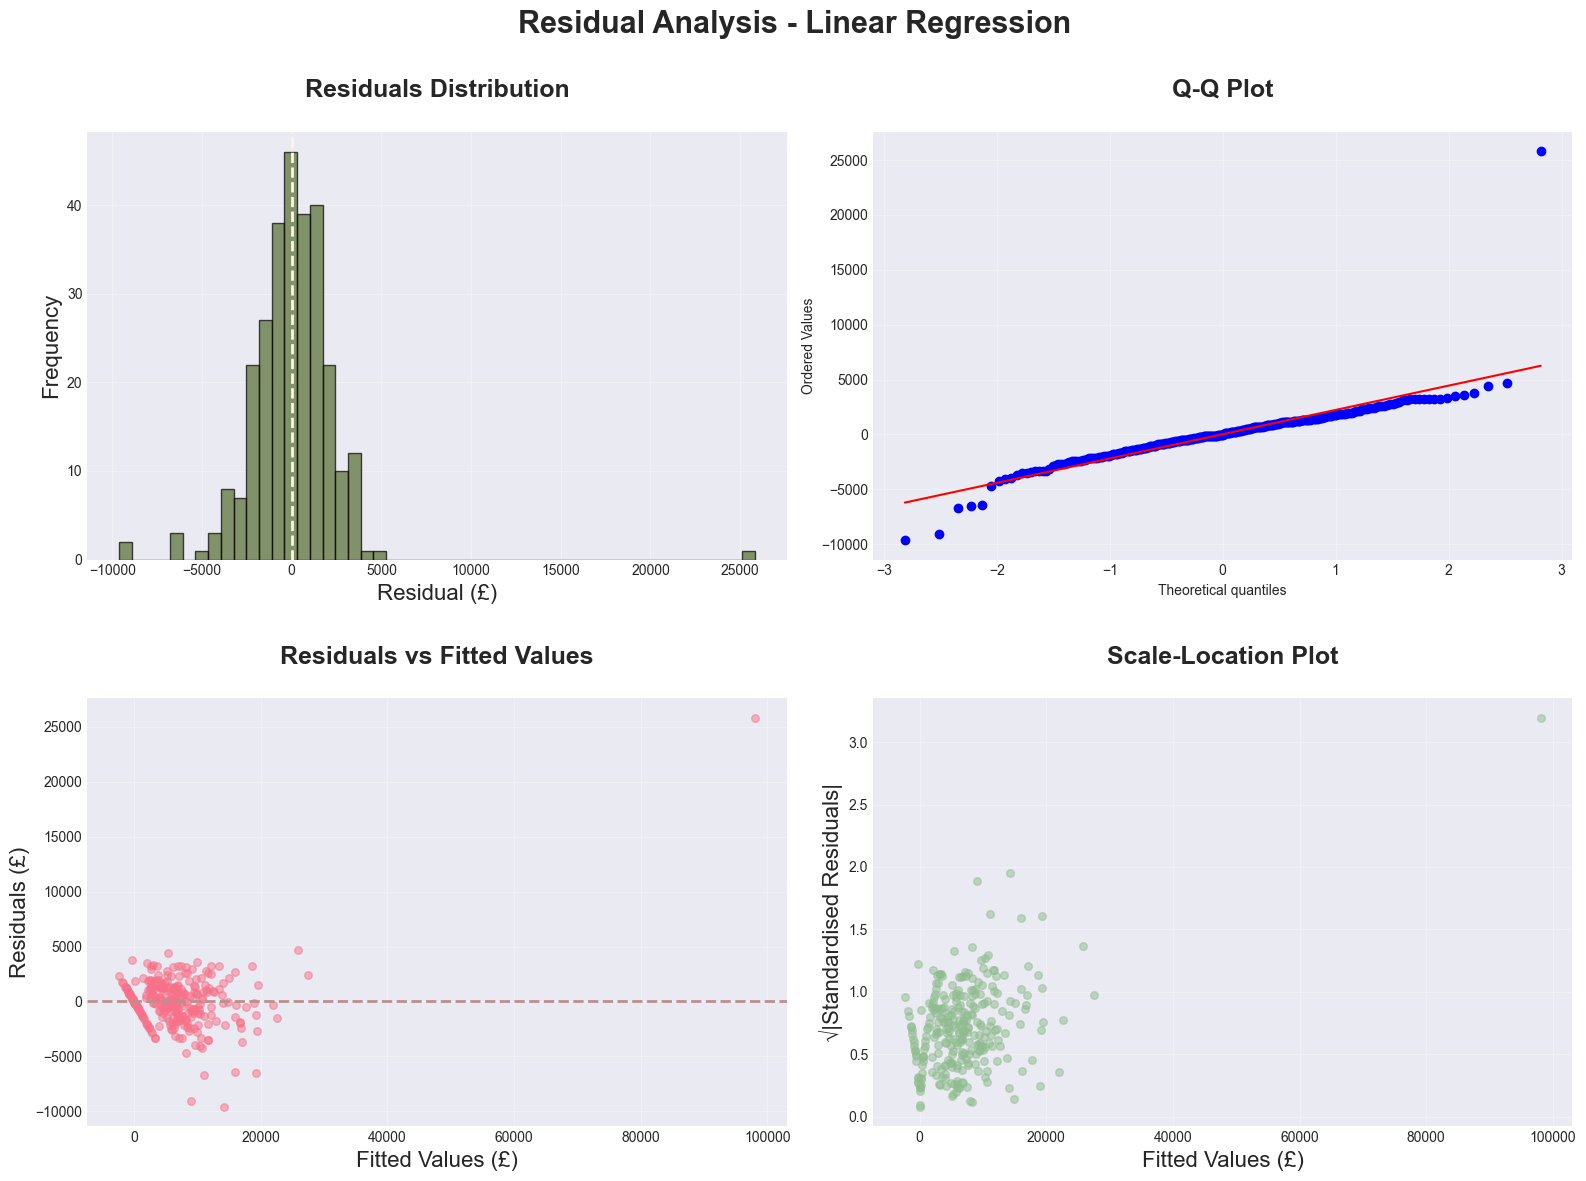


Residual Analysis Statistics:
******************************
Mean of residuals: £23.6049
Standard deviation: £2531.18
Skewness: 3.1935
Kurtosis: 37.5589

Normality test (D'Agostino-Pearson):
  p-value: 0.0000
  Residuals may not be normally distributed (p < 0.05)


In [93]:
# Comprehensive residual analysis for best model

plt.figure(figsize=(16, 12))
plt.suptitle(f"Residual Analysis - {best_model}\n", fontsize=22, fontweight="bold")

# Residual distribution
plt.subplot(2, 2, 1)
plt.hist(residuals, bins=50, color="DarkOliveGreen", edgecolor="black", alpha=0.7)
plt.axvline(0, color="Cornsilk", linestyle="--", linewidth=2)
plt.xlabel("Residual (£)", fontsize=16)
plt.ylabel("Frequency", fontsize=16)
plt.title("Residuals Distribution\n", fontweight="bold", fontsize=18)
plt.grid(alpha=0.3)

# Q-Q Plot
plt.subplot(2, 2, 2)
stats.probplot(residuals, dist="norm", plot=plt.gca())
plt.title("Q-Q Plot\n", fontweight="bold", fontsize=18)
plt.grid(alpha=0.3)

# Residuals vs Fitted
plt.subplot(2, 2, 3)
plt.scatter(best_predictions, residuals, alpha=0.5, s=30)
plt.axhline(0, color="RosyBrown", linestyle="--", linewidth=2)
plt.xlabel("Fitted Values (£)", fontsize=16)
plt.ylabel("Residuals (£)", fontsize=16)
plt.title("\nResiduals vs Fitted Values\n", fontweight="bold", fontsize=18)
plt.grid(alpha=0.3)

# Scale-Location Plot
plt.subplot(2, 2, 4)
std_resid = residuals / residuals.std()
plt.scatter(best_predictions, np.sqrt(np.abs(std_resid)), s=30, alpha=0.5, color="DarkSeaGreen")
plt.xlabel("Fitted Values (£)", fontsize=16)
plt.ylabel("√|Standardised Residuals|", fontsize=16)
plt.title("\nScale-Location Plot\n", fontweight="bold", fontsize=18)
plt.grid(alpha=0.3)

plt.tight_layout()
plt.show()

# Statistical summary
print("\nResidual Analysis Statistics:")
print("*" * 30)
print(f"Mean of residuals: £{residuals.mean():.4f}")
print(f"Standard deviation: £{residuals.std():.2f}")
print(f"Skewness: {stats.skew(residuals):.4f}")
print(f"Kurtosis: {stats.kurtosis(residuals):.4f}")

# Normality test
_, p_norm = stats.normaltest(residuals)
print("\nNormality test (D'Agostino-Pearson):")
print(f"  p-value: {p_norm:.4f}")
if p_norm > 0.05:
    print("  Residuals appear to be normally distributed (p > 0.05)")
else:
    print("  Residuals may not be normally distributed (p < 0.05)")


## Step 12: Country Specific Analysis and Forecasting

Countries in dataset: ['Ireland' 'Northern Ireland' 'Scotland' 'Wales' 'England']

Profit by country in test period:
Ireland: £401,235.73
Northern Ireland: £375,833.89
Scotland: £370,569.27
Wales: £393,088.81
England: £442,150.93


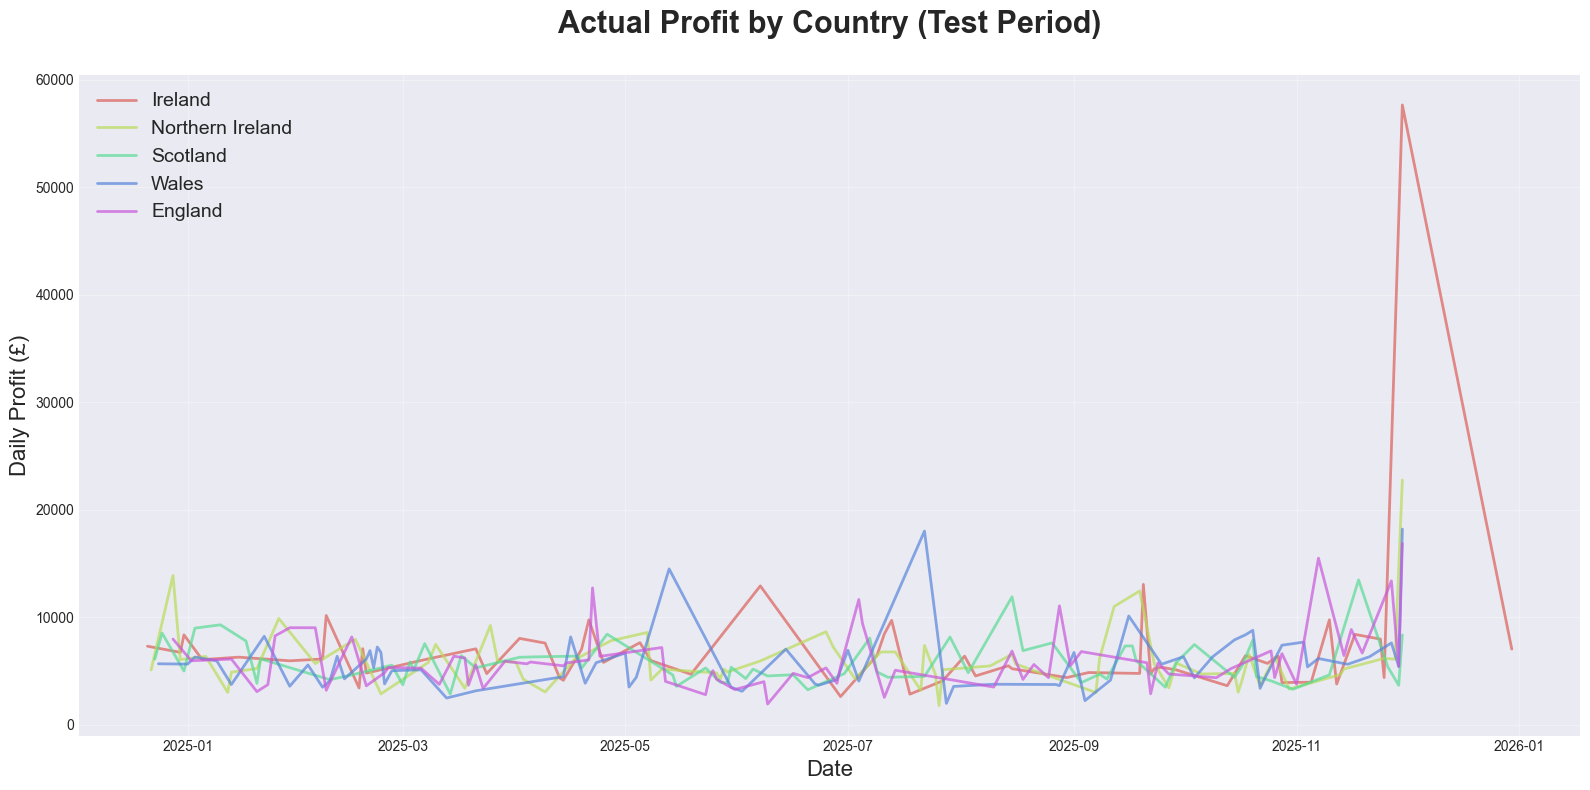

In [94]:
# Analyse forecast performance by country
# Filter test-period rows
test_period = df_clean[df_clean['Date'].isin(y_test.index)]

# Aggregate profit by date and country
country_daily_test = (test_period.groupby(['Date', 'Country'])['Profit(£)'].sum().reset_index())

# List of unique countries
countries = country_daily_test['Country'].unique()

print(f"Countries in dataset: {countries}")
print("\nProfit by country in test period:")

# Print total profit per country
for c in countries:
    total_profit = country_daily_test.loc[country_daily_test['Country'] == c, 'Profit(£)'].sum()
    print(f"{c}: £{total_profit:,.2f}")

# Visualisation 
plt.figure(figsize=(16, 8))
palette = sns.color_palette('hls', len(countries))

for i, c in enumerate(countries):
    # Aggregate by date for each country
    daily = (country_daily_test[country_daily_test['Country'] == c].groupby('Date')['Profit(£)'].sum())
    
    plt.plot(
        daily.index,
        daily.values,
        label=c,
        linewidth=2,
        alpha=0.7,
        color=palette[i]
    )

plt.xlabel("Date", fontsize=16)
plt.ylabel("Daily Profit (£)", fontsize=16)
plt.title("Actual Profit by Country (Test Period)\n", fontsize=22, fontweight="bold")
plt.grid(alpha=0.3)
plt.legend(fontsize=14)
plt.tight_layout()
plt.show()
